# Riot Project Version 2 — presentation figure gallery

**Original familiar-alternative research question:** “When a player picks their main, how often does the model favor a previously played alternative with a better matchup, and does personalization change that decision?”

Browse this notebook and copy its inline figures/tables. Descriptive outcomes use **matched usable training player-games**; decision figures use the **existing saved test-period, actual-main-pick reports**. Cohorts stay separate. No collection, preparation pipeline, fitting, selection, or predictive evaluation runs. No image exports are created.

**Contents**

1. [Cohort overview and recorded history](#overview)
2. [Descriptive experience, OTP rate, main choice and mastery groups](#eda)
3. [Blue/red side-related descriptions](#side)
4. [Model outline and primary parameter estimates](#model-outline)
5. [Model curves, calibration and predictive performance](#model-findings)
6. [Main versus alternative — central decision figures](#decisions)
7. [Illustrative games, with both prediction modes](#examples)
8. [Appendix: clean EDA, grouped curves, secondary estimates and assumptions](#appendix)
9. [Limitations and strongest figures for David](#limitations)

**Qualifications throughout:** Master is a legacy **Master-labeled** cohort without dated rank verification, benchmarked against Global **Master+**. Broad ranks are collection-time labels, not verified patch-period ranks, and use exact-tier Global benchmarks. Both analyses use full-patch external rates and previously examined test outcomes.

[Section 10: expanded published-matchup alternatives, including zero recorded experience](#expanded-decisions) addresses the broader question. Earlier figures and tables remain familiar-only results.

**New analysis:** [Section 12 — project-wide min50 refits](#min50-refits), with fresh shared/grouped fits and updated EDA, parameters, validation/test results and expanded decisions. Earlier results remain preserved in their original scopes.

In [2]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
from pathlib import Path
import ast, hashlib, importlib.metadata as metadata, json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter, MaxNLocator
from IPython.display import display, Markdown
from scipy.linalg import helmert

start=Path.cwd().resolve()
ROOT=next(p for p in [start,*start.parents] if (p/'hlr_model/main_pick_decision_report.py').is_file())
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':12,'axes.titlesize':15,
    'axes.labelsize':12,'xtick.labelsize':10,'ytick.labelsize':11,'legend.fontsize':10,
    'figure.facecolor':'white','axes.spines.top':False,'axes.spines.right':False,'savefig.facecolor':'white'})
COHORTS={
 'Bronze–Diamond':dict(folder='broad_rank_mastery_v1',version='20261028T193830350096Z_5a469939',notebook='broad_rank_modeling.ipynb',helper='broad_rank_modeling.py',benchmark='Global exact-tier'),
 'Master-labeled':dict(folder='master_cohort_mastery_v1',version='20261028T214327398991Z_4beeb7d4',notebook='master_cohort_modeling.ipynb',helper='master_cohort_modeling.py',benchmark='Global Master+')}
RANKS=['BRONZE','SILVER','GOLD','PLATINUM','EMERALD','DIAMOND']
GROUPS=list('ABCDEFGHIJ')+['Unclassified']
EXPERIENCE=['0','1–4','5–9','10–19','20–49','50+']
USAGE=['0–20%','>20–40%','>40–60%','>60–80%','>80–100%']
MODES=['Reference player','Personalized']
CLASSES=['Alternative favored','Main favored over selected alternative','Uncertain']
COLORS={'observed':'#2563A6','benchmark':'#C58B2A','personalized':'#7656A4','uncertain':'#AAB2BD','red':'#C84444'}
def digest(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as handle:
        for block in iter(lambda:handle.read(1024*1024),b''):h.update(block)
    return h.hexdigest()
D={}
for label,info in COHORTS.items():
    path=ROOT/'hlr_model/data/analyses'/info['folder']/info['version']
    preparation=json.loads((path/'preparation_manifest.json').read_text())
    final=json.loads((path/'final_artifact_manifest.json').read_text())
    hashes={**final.get('output_sha256',final.get('sha256',{})),**preparation['output_sha256']}
    identity=preparation['identity'];identity=json.loads(identity) if isinstance(identity,str) else identity
    assert digest(ROOT/'hlr_model'/info['helper'])==identity['helper_sha256']
    def checked(name,path=path,hashes=hashes):
        assert name in hashes and digest(path/name)==hashes[name], f'Artifact changed: {path/name}'
        return path/name
    required=['prepared_played.parquet','group_experience_curves.parquet','calibration.csv','evaluation_metrics.csv',
              'fits/shared/fit_manifest.json','fits/shared/fit_status.json','fits/shared/sampling_diagnostics.csv',
              'fits/grouped/fit_manifest.json','fits/grouped/fit_status.json','fits/grouped/sampling_diagnostics.csv']
    for name in required:checked(name)
    fields=['puuid','match_id','timestamp','champion_id','prior_main_champion_id','is_main_champion',
        'initial_history_games','prior_total_games','prior_champion_usage_share','n_recorded','historical_wr_beta11','log_total',
        'matchup_probability','mastery_group','model_rank','split','usable_data','included_in_primary_model','team_id','side']
    full=pd.read_parquet(path/'prepared_played.parquet',columns=fields)
    train=pd.read_parquet(path/'prepared_played.parquet',columns=fields+['win'],filters=[('split','==','train')])
    train=train.loc[train.usable_data].copy()
    assert train.split.eq('train').all() and train.win.isin([0,1]).all()
    assert train.matchup_probability.between(0,1).all() and not train.duplicated(['puuid','match_id']).any()
    train['usage_share']=train.n_recorded/train.prior_total_games.where(train.prior_total_games.gt(0))
    assert np.allclose(train.usage_share,train.prior_champion_usage_share,equal_nan=True)
    train['experience_bin']=pd.cut(train.n_recorded,[-.5,.5,4.5,9.5,19.5,49.5,np.inf],labels=EXPERIENCE)
    train['usage_bin']=pd.cut(train.usage_share,[0,.2,.4,.6,.8,1],labels=USAGE,include_lowest=True)
    train['main_choice']=np.where(train.champion_id.eq(train.prior_main_champion_id),'Recorded main','Another champion')
    known=train.prior_main_champion_id.notna()
    assert train.loc[known,'champion_id'].eq(train.loc[known,'prior_main_champion_id']).equals(train.loc[known,'is_main_champion'])
    # Discover the report folder from the executed CURRENT reporting section, not a guessed folder suffix.
    current=json.loads((ROOT/'hlr_model'/info['notebook']).read_text());reports=[]
    for cell in current['cells']:
        if cell['cell_type']=='code' and 'MAIN_PICK_REPORT=' in ''.join(cell['source']):
            for output in cell.get('outputs',[]):
                text=output.get('text','');text=''.join(text) if isinstance(text,list) else text
                for line in text.splitlines():
                    if line.startswith('New report directory:'):reports.append(Path(line.split(':',1)[1].strip()))
    assert reports, 'Execute/discover the existing reporting section first.'
    report=reports[-1].resolve();assert report.is_relative_to(path.resolve())
    parquet_files=list(report.glob('*.parquet'));csv_files=list(report.glob('*.csv'))
    assert len(parquet_files)==1 and len(csv_files)==1, 'Investigate ambiguous report schemas.'
    decisions=pd.read_parquet(parquet_files[0]);summary=pd.read_csv(csv_files[0])
    assert {'mode','main_champion_id','alternative_champion_id','classification','eligible_alternatives','highest_mean_choice_id'}<=set(decisions)
    assert {'section','mode','measure','count','denominator','percent','players'}<=set(summary)
    provenance=decisions.attrs['provenance']
    assert provenance['source_version']==path.name
    assert provenance['report_helper_sha256']==digest(ROOT/'hlr_model/main_pick_decision_report.py')
    for name,h in provenance['input_sha256'].items():assert digest(path/name)==h
    assert 'win' not in decisions and not decisions.duplicated(['puuid','match_id','mode']).any()
    assert set(decisions['mode'])==set(MODES)
    test=full.loc[full.split.eq('test')];main=test.loc[test.champion_id.eq(test.prior_main_champion_id)]
    joined=decisions.merge(main[['puuid','match_id','champion_id']],on=['puuid','match_id'],validate='many_to_one')
    assert len(joined)==len(decisions) and joined.main_champion_id.eq(joined.champion_id).all()
    expected={'Master-labeled':(324,392),'Bronze–Diamond':(233,288)}[label]
    assert len(decisions)//2==expected[0] and len(main)==expected[1], 'Investigate a changed report subset; do not force counts.'
    # Reconcile saved game-level selection with existing paired means, without making new predictions.
    saved=pd.read_parquet(path/'paired_recommendations.parquet',filters=[('model','==','shared'),('reference','==','main')])
    saved=saved.merge(main[['puuid','match_id']],on=['puuid','match_id'],validate='many_to_one')
    top=saved.sort_values(['puuid','match_id','mode','alternative_probability','alternative_champion_id'],ascending=[True,True,True,False,True]).drop_duplicates(['puuid','match_id','mode'])
    top['mode']=top['mode'].map({'general':'Reference player','personalized':'Personalized'})
    same=decisions.merge(top,on=['puuid','match_id','mode'],suffixes=('_decision','_pair'),validate='one_to_one')
    assert len(same)==len(decisions) and same.alternative_champion_id_decision.eq(same.alternative_champion_id_pair).all()
    for field in ['difference_pp','low_pp','high_pp','probability_alternative_higher']:
        np.testing.assert_allclose(same[field+'_decision'],same[field+'_pair'],rtol=0,atol=1e-12)
    for mode,part in decisions.groupby('mode'):
        counts=part.classification.value_counts().reindex(CLASSES,fill_value=0)
        reported=summary.loc[summary.section.eq('classification')&summary['mode'].eq(mode)].set_index('measure').reindex(CLASSES)
        assert np.array_equal(counts.to_numpy(),reported['count'].to_numpy()) and reported.denominator.eq(len(part)).all()
    selected=None
    if label=='Master-labeled':selected=json.loads(checked('source_audit.json').read_text())['selected_players']
    else:
        original=identity['source']['original_cohort']
        cp=ROOT/'hlr_model/data/runs/broad_na_16_19_seed_161926/processed'/original['snapshot']/'player_cohort.parquet'
        assert digest(cp)==original['files_sha256']['player_cohort.parquet'];selected=len(pd.read_parquet(cp,columns=['puuid']))
    D[label]=dict(path=path,checked=checked,full=full,train=train,decisions=decisions,summary=summary,report_path=report,
        curves=pd.read_parquet(path/'group_experience_curves.parquet'),calibration=pd.read_csv(path/'calibration.csv'),selected=selected,
        provenance=provenance,model_source=(ROOT/'hlr_model'/info['helper']).read_text())
print('Interpreter:',sys.executable)
print('Plotting environment:',{name:metadata.version(name) for name in ['numpy','pandas','matplotlib','pyarrow']})
print('Verified completed artifact hashes and current report provenance. Only saved tables/draws will be read.')
for label,d in D.items():print(label,'decision report discovered:',d['report_path'])


Interpreter: /Users/minhho-hoang/Documents/riot_proj/riot-game-prediction/.venv-modeling/bin/python
Plotting environment: {'numpy': '1.26.4', 'pandas': '2.2.3', 'matplotlib': '3.9.2', 'pyarrow': '17.0.0'}
Verified completed artifact hashes and current report provenance. Only saved tables/draws will be read.
Bronze–Diamond decision report discovered: /Users/minhho-hoang/Documents/riot_proj/riot-game-prediction/hlr_model/data/analyses/broad_rank_mastery_v1/20261028T193830350096Z_5a469939/reports/main_pick_decisions_v1
Master-labeled decision report discovered: /Users/minhho-hoang/Documents/riot_proj/riot-game-prediction/hlr_model/data/analyses/master_cohort_mastery_v1/20261028T214327398991Z_4beeb7d4/reports/main_pick_decisions_v1


<a id="overview"></a>
## 1. Cohort overview and recorded history

Player-games are focal-player records, not unique matches. The full collected target cohort is distinct from the retained usable modeling sample; Master has 15 selected seeds with no target games.

In [3]:
overview=[];splits=[];histories={}
for label,d in D.items():
    full=d['full'];usable=full.loc[full.included_in_primary_model]
    overview.append(dict(cohort=label,selected_players=d['selected'],players_with_targets=full.puuid.nunique(),
        full_target_player_games=len(full),full_target_unique_matches=full.match_id.nunique(),
        usable_model_players=usable.puuid.nunique(),usable_model_player_games=len(usable)))
    for split in ['train','validation','test']:
        f=usable.loc[usable.split.eq(split)]
        splits.append(dict(cohort=label,split=split,player_games=len(f),players=f.puuid.nunique(),unique_matches=f.match_id.nunique()))
    h=full[['puuid','initial_history_games']].drop_duplicates()
    assert h.puuid.is_unique;histories[label]=h
    for split in ['train','validation','test']:assert not usable.loc[usable.split.eq(split)].duplicated(['puuid','match_id']).any()
display(pd.DataFrame(overview).set_index('cohort'))
display(pd.DataFrame(splits).set_index(['cohort','split']))


,selected_players,players_with_targets,full_target_player_games,full_target_unique_matches,usable_model_players,usable_model_player_games
cohort,,,,,,
Bronze–Diamond,300,300,5706,5686,300,5687
Master-labeled,200,185,7238,6806,184,7200


player_games  players  unique_matches
cohort         split                                            
Bronze–Diamond train               3907      265            3892
               validation           852      147             850
               test                 928      152             925
Master-labeled train               5086      177            4746
               validation          1049      128            1005
               test                1065      127            1019

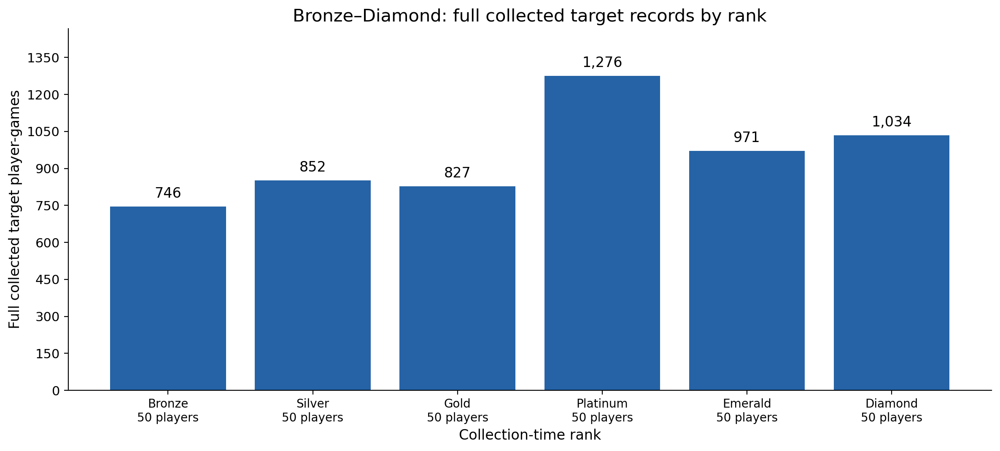

In [4]:
counts=D['Bronze–Diamond']['full'].groupby('model_rank').agg(player_games=('match_id','size'),players=('puuid','nunique')).reindex(RANKS)
fig,ax=plt.subplots(figsize=(12,5.5))
bars=ax.bar(range(6),counts.player_games,color=COLORS['observed'])
ax.bar_label(bars,labels=[f'{r.player_games:,}' for r in counts.itertuples()],padding=5)
ax.set(xticks=range(6),xticklabels=[f'{rank.title()}\n{r.players} players' for rank,r in zip(RANKS,counts.itertuples())],
       ylabel='Full collected target player-games',xlabel='Collection-time rank',title='Bronze–Diamond: full collected target records by rank')
ax.set_ylim(0,counts.player_games.max()*1.15);ax.yaxis.set_major_locator(MaxNLocator(integer=True));fig.tight_layout();plt.show()


Each rank contributes 50 players, but their numbers of collected target games differ. These are all saved target player-games, including rows later excluded or purged; shared matches can appear more than once.

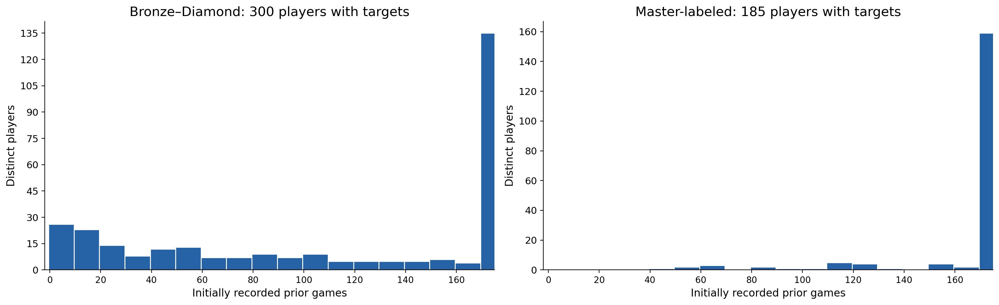

,players,minimum,median,maximum,players_with_170,players_with_fewer_170
cohort,,,,,,
Bronze–Diamond,300,0,139.5,170,135,165
Master-labeled,185,46,170.0,170,159,26


In [5]:
fig,axes=plt.subplots(1,2,figsize=(16,5),sharex=True)
history_table=[]
for ax,(label,h) in zip(axes,histories.items()):
    depth=h.initial_history_games
    ax.hist(depth,bins=np.arange(-.5,180,10),color=COLORS['observed'],edgecolor='white')
    ax.set(title=f'{label}: {len(h)} players with targets',xlabel='Initially recorded prior games',ylabel='Distinct players',xlim=(-2,175))
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    history_table.append(dict(cohort=label,players=len(h),minimum=int(depth.min()),median=depth.median(),maximum=int(depth.max()),
        players_with_170=int(depth.eq(170).sum()),players_with_fewer_170=int(depth.lt(170).sum())))
fig.tight_layout();plt.show();display(pd.DataFrame(history_table).set_index('cohort'))


Initial history is capped at 170 but is not uniformly 170: broad has a median of 139.5, while Master’s median is 170. These distributions include all players with target records (including the incomplete-history Master player later excluded); Master’s 15 seeds without targets are not treated as zero-experience active players.

<a id="eda"></a>
## 2. Matched training EDA

All observed-versus-benchmark comparisons below use the same **usable training player-games** within each cohort. “OTP rate” means the selected champion’s share of prior all-role games; main means the largest strictly prior all-role champion count, with the existing smallest-ID tie-break and no percentage threshold. Recorded experience is bounded recorded history, not lifetime practice.

Wilson intervals are approximate and ignore repeated-player/shared-match dependence. No uncertainty interval is invented for the external benchmark. Rate axes are zoomed to the displayed observed rates, benchmarks and interval bounds plus five percentage points on each side, clamped to 0–100%. Matching cohort panels share limits; clean copies retain the same limits.

In [4]:
def rate_summary(frame,category,levels):
    out=frame.groupby(category,observed=True).agg(wins=('win','sum'),games=('win','size'),players=('puuid','nunique'),baseline=('matchup_probability','mean')).reindex(levels)
    out[['wins','games','players']]=out[['wins','games','players']].fillna(0).astype(int)
    games=out.games.where(out.games.gt(0));p=out.wins/games;z=1.959963984540054
    center=(p+z*z/(2*games))/(1+z*z/games)
    half=z*np.sqrt(p*(1-p)/games+z*z/(4*games**2))/(1+z*z/games)
    out['observed']=p;out['low']=center-half;out['high']=center+half
    return out

def percentage_limits(*values):
    # All rate charts below display percentages: five percentage points = 5.
    displayed=np.concatenate([np.asarray(value,dtype=float).ravel() for value in values])
    finite=displayed[np.isfinite(displayed)]
    return (max(0.,finite.min()-5),min(100.,finite.max()+5)) if finite.size else (0.,100.)

def set_rate_limits(ax,limits):
    ax.set_ylim(*limits)
    ax.yaxis.set_major_locator(MaxNLocator(nbins=6,steps=[1,2,2.5,5,10]))
    ax.yaxis.set_major_formatter(PercentFormatter(100))

def rate_axes(ax,summary,title,xlabel,*,intervals=True,benchmark_label='Mean raw matchup benchmark',limits=None):
    x=np.arange(len(summary),dtype=float)
    if summary.index[-1]=='Unclassified':x[-1]+=.7
    errors=100*np.array([summary.observed-summary.low,summary.high-summary.observed]) if intervals else None
    observed=ax.errorbar(x,100*summary.observed,yerr=errors,fmt='o-',color=COLORS['observed'],capsize=4,
                        label='Observed WR'+(' (95% Wilson)' if intervals else ''))
    benchmark,=ax.plot(x,100*summary.baseline,'s--',color=COLORS['benchmark'],label=benchmark_label)
    np.testing.assert_array_equal(observed.lines[0].get_xdata(),benchmark.get_xdata())
    tick_labels=([f'{label}\n{row.games}g\n{row.players}p' for label,row in zip(summary.index,summary.itertuples())] if len(summary)>8
                 else [f'{label}\n{row.games:,} games\n{row.players} players' for label,row in zip(summary.index,summary.itertuples())])
    if len(summary)>8:xlabel+=' (g = player-games; p = players)'
    ax.set(xticks=x,xticklabels=tick_labels,
           xlabel=xlabel,ylabel='Win rate (%)',title=title)
    if limits is None:limits=percentage_limits(100*summary[['observed','baseline','low','high']])
    set_rate_limits(ax,limits)
    ax.yaxis.set_major_formatter(PercentFormatter(100));ax.grid(axis='y',alpha=.2);ax.legend(fontsize=9)

def paired_rates(category,levels,title,xlabel,*,intervals=True):
    summaries={}
    for label,d in D.items():
        frame=d['train']
        if category=='main_choice':frame=frame.loc[frame.prior_main_champion_id.notna()]
        summaries[label]=rate_summary(frame,category,levels)
    # Retain Wilson bounds when choosing limits for the clean copies too.
    limits=percentage_limits(*(100*s[['observed','baseline','low','high']] for s in summaries.values()))
    fig,axes=plt.subplots(1,2,figsize=(18,6),sharey=True)
    for ax,(label,summary) in zip(axes,summaries.items()):
        rate_axes(ax,summary,label+' — usable training',xlabel,intervals=intervals,limits=limits,
                  benchmark_label=COHORTS[label]['benchmark']+' benchmark')
    fig.suptitle(title,fontsize=18);fig.tight_layout();plt.show()


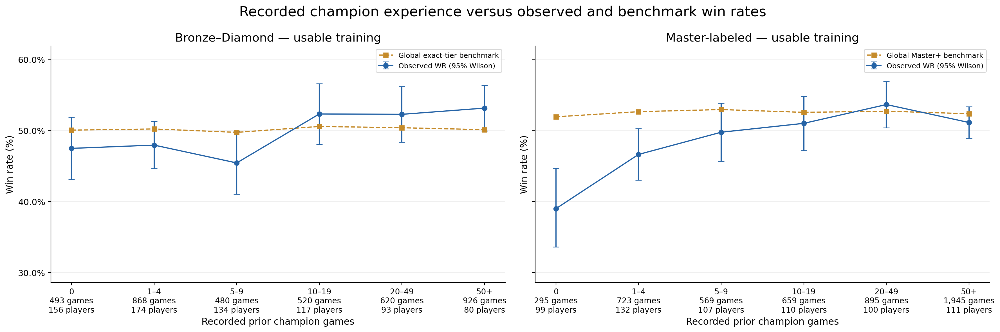

In [5]:
paired_rates('experience_bin',EXPERIENCE,'Recorded champion experience versus observed and benchmark win rates','Recorded prior champion games')

Master’s descriptive WR rises from low recorded experience to moderate experience; broad has a weaker-looking raw pattern. These unadjusted training descriptions mix player/champion selection and historical WR, so they are not practice-effect estimates.

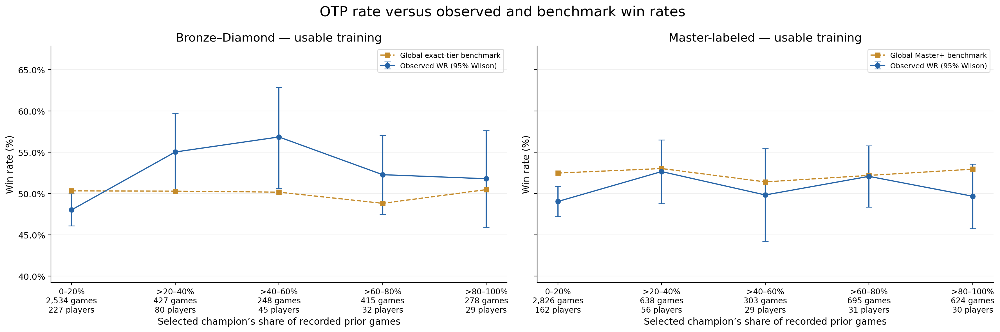

In [6]:
paired_rates('usage_bin',USAGE,'OTP rate versus observed and benchmark win rates','Selected champion’s share of recorded prior games')

The OTP-rate pattern is not a guaranteed monotone advantage in either cohort. Undefined shares at zero total history are excluded from this chart, not filled; the benchmark and observed rates still use identical rows within every displayed category. Broad excludes five training rows with undefined usage shares; Master excludes none.

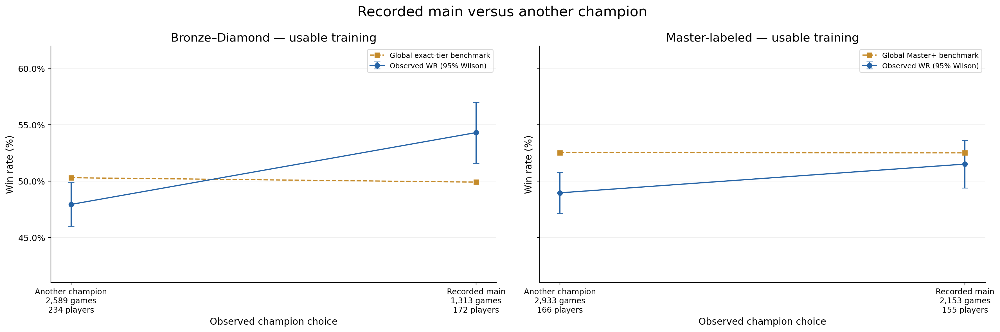

In [7]:
paired_rates('main_choice',['Another champion','Recorded main'],'Recorded main versus another champion','Observed champion choice')

Another champion is left and recorded main right, with observed and benchmark markers at exactly the same category positions. Main choice is observational and uses no new OTP cutoff; the intervals do not account for repeated-player dependence. Broad excludes five training rows without an identifiable prior main; Master excludes none.

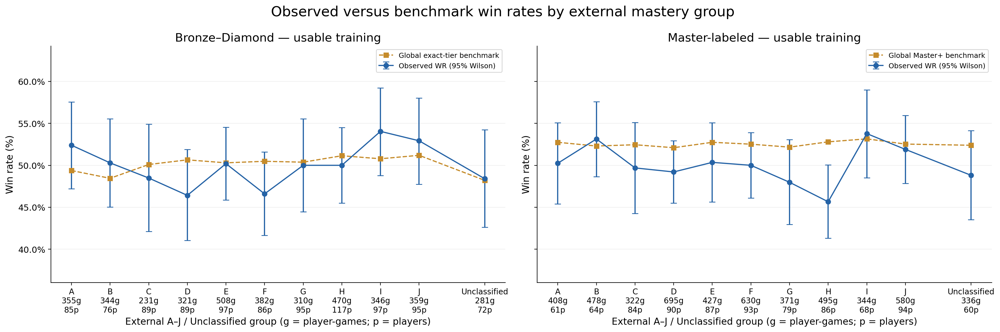

In [8]:
paired_rates('mastery_group',GROUPS,'Observed versus benchmark win rates by external mastery group','External A–J / Unclassified group')

External groups show different observed rates, but their workbook order is not a guaranteed ordering of fitted effects. Counts and players vary by group; these unadjusted rates do not establish group-specific causal learning gains.

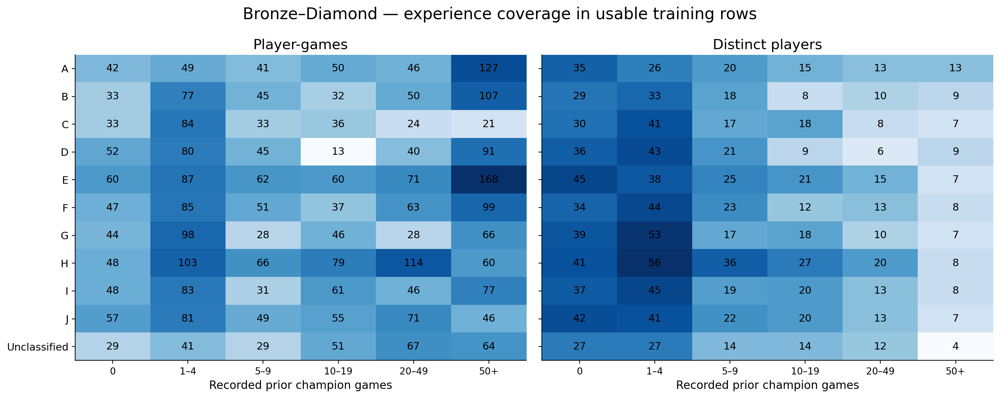

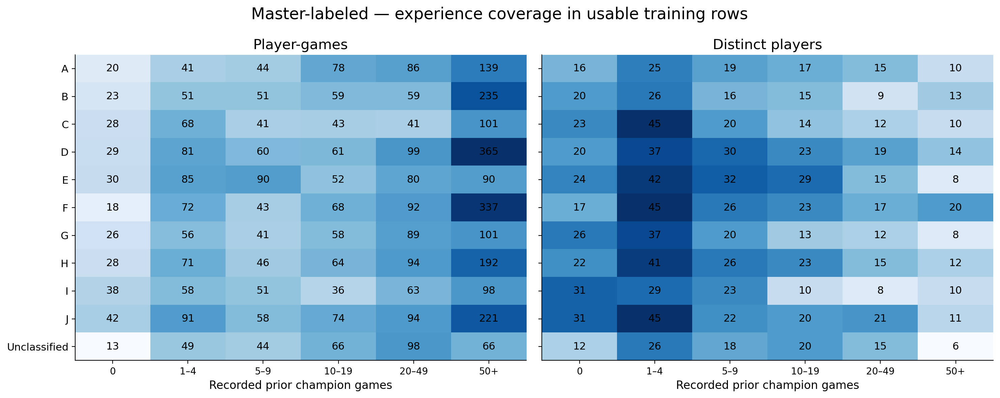

In [11]:
coverage_tables={}
for label,d in D.items():
    coverage=d['train'].groupby(['mastery_group','experience_bin'],observed=False).agg(games=('win','size'),players=('puuid','nunique')).reset_index()
    coverage_tables[label]=coverage
    fig,axes=plt.subplots(1,2,figsize=(15,6),sharey=True)
    for ax,value,title in zip(axes,['games','players'],['Player-games','Distinct players']):
        grid=coverage.pivot(index='mastery_group',columns='experience_bin',values=value).reindex(index=GROUPS,columns=EXPERIENCE).fillna(0)
        ax.imshow(np.log1p(grid.to_numpy()),aspect='auto',cmap='Blues')
        for i in range(len(GROUPS)):
            for j in range(len(EXPERIENCE)):ax.text(j,i,str(int(grid.iloc[i,j])) if grid.iloc[i,j] else '—',ha='center',va='center',fontsize=11)
        ax.set(xticks=range(6),xticklabels=EXPERIENCE,yticks=range(11),yticklabels=GROUPS,xlabel='Recorded prior champion games',title=title)
    fig.suptitle(label+' — experience coverage in usable training rows',fontsize=17);fig.tight_layout();plt.show()


High experience is more broadly represented in Master, but group coverage is uneven and players can appear in multiple cells. Shading uses log(1+count), while every label is the actual count; a dash means no observed support.

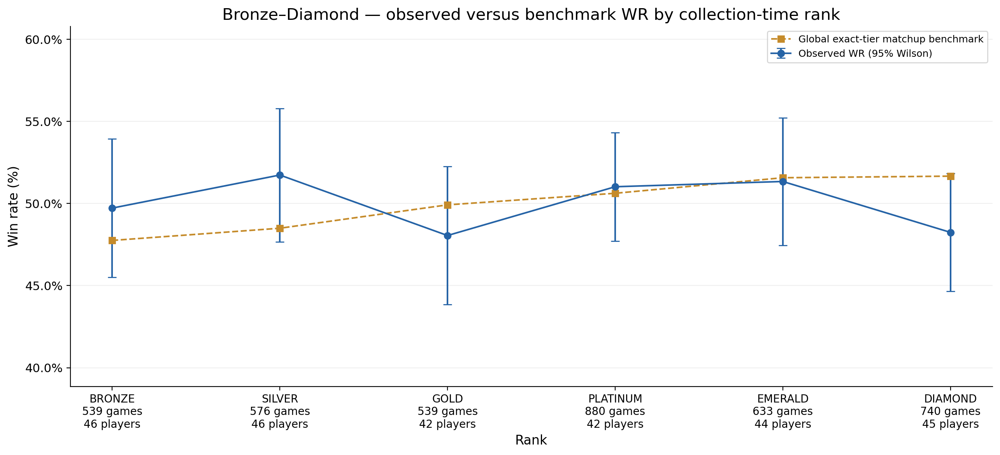

In [9]:
rank_rates=rate_summary(D['Bronze–Diamond']['train'],'model_rank',RANKS)
fig,ax=plt.subplots(figsize=(13,6))
rate_axes(ax,rank_rates,'Bronze–Diamond — observed versus benchmark WR by collection-time rank','Rank',benchmark_label='Global exact-tier matchup benchmark')
fig.tight_layout();plt.show()


Observed and benchmark rates are compared on identical usable training rows within each rank. These descriptive differences are not a formal rank-interaction analysis, and the rank labels were not historically verified for the target patch.

<a id="side"></a>
## 3. Side-related descriptions

Stored side labels are checked against the existing `longitudinal_pipeline.player_record` mapping: **team 100 → blue; team 200 → red**. Nothing is inferred from participant order. All outcomes here remain usable training outcomes.

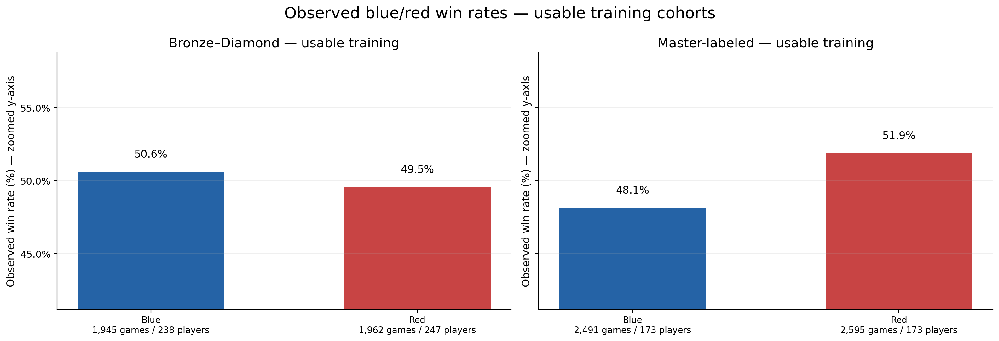

In [4]:
side_tables={label:rate_summary(d['train'],'side',['blue','red']) for label,d in D.items()}
side_limits=percentage_limits(*(100*s[['observed','low','high']] for s in side_tables.values()))
fig,axes=plt.subplots(1,2,figsize=(16,5.5),sharey=True)
for ax,(label,d) in zip(axes,D.items()):
    train=d['train']
    assert train.team_id.isin([100,200]).all() and train.side.eq(train.team_id.map({100:'blue',200:'red'})).all()
    summary=side_tables[label]
    x=np.arange(2);errors=100*np.array([summary.observed-summary.low,summary.high-summary.observed])
    ax.bar(x,100*summary.observed,color=[COLORS['observed'],COLORS['red']],width=.55)
    for i,row in enumerate(summary.itertuples()):ax.text(i,100*row.observed+1,f'{100*row.observed:.1f}%',ha='center')
    ax.set(xticks=x,xticklabels=[f'{side.title()}\n{r.games:,} games / {r.players} players' for side,r in zip(summary.index,summary.itertuples())],
           title=label+' — usable training',ylabel='Observed win rate (%) — zoomed y-axis')
    set_rate_limits(ax,side_limits)
    ax.yaxis.set_major_formatter(PercentFormatter(100));ax.grid(axis='y',alpha=.2)
fig.suptitle('Observed blue/red win rates — usable training cohorts',fontsize=18);fig.tight_layout();plt.show()


These rate bars use a **zoomed y-axis**; bar lengths are truncated, so compare the labeled rates. Error bars are omitted for clarity; the shared axis limits retain the underlying Wilson bounds. Blue/red rates describe the sampled focal-player records; they need not add to 100% because both teams were not sampled equally. These unadjusted rates do not establish a side advantage, and repeated players/matches can make Wilson intervals too narrow.

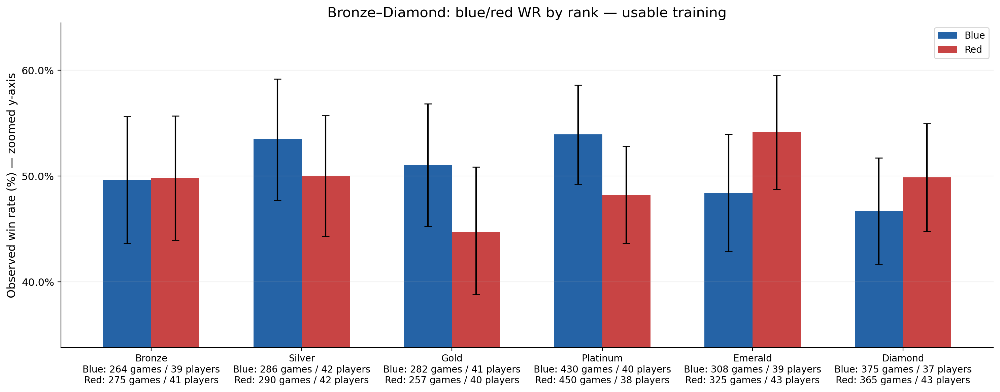

In [11]:
frame=D['Bronze–Diamond']['train'];side_by_rank=frame.groupby(['model_rank','side']).agg(
    wins=('win','sum'),games=('win','size'),players=('puuid','nunique'),baseline=('matchup_probability','mean'))
rank_side_summaries={side:rate_summary(frame.loc[frame.side.eq(side)],'model_rank',RANKS) for side in ['blue','red']}
rank_side_limits=percentage_limits(*(100*s[['observed','low','high']] for s in rank_side_summaries.values()))
fig,ax=plt.subplots(figsize=(15,6));x=np.arange(6);width=.32
for side,offset,color in [('blue',-width/2,COLORS['observed']),('red',width/2,COLORS['red'])]:
    summary=rank_side_summaries[side]
    errors=100*np.array([summary.observed-summary.low,summary.high-summary.observed])
    ax.bar(x+offset,100*summary.observed,width,color=color,yerr=errors,capsize=4,label=side.title())
labels=[]
for rank in RANKS:
    b=side_by_rank.loc[(rank,'blue')];r=side_by_rank.loc[(rank,'red')]
    labels.append(f'{rank.title()}\nBlue: {int(b.games)} games / {int(b.players)} players\nRed: {int(r.games)} games / {int(r.players)} players')
ax.set(xticks=x,xticklabels=labels,ylabel='Observed win rate (%) — zoomed y-axis',title='Bronze–Diamond: blue/red WR by rank — usable training')
set_rate_limits(ax,rank_side_limits)
ax.yaxis.set_major_formatter(PercentFormatter(100));ax.grid(axis='y',alpha=.2);ax.legend();fig.tight_layout();plt.show()


These rate bars also use a **zoomed y-axis**. The side pattern varies across the sampled rank groups and should not be read as a formal rank-by-side effect. Counts are focal-player games and distinct players; approximate Wilson intervals omit within-player/shared-match dependence.

### Blue side versus red side across sampled ranks

Bronze–Diamond uses the broad cohort; Master uses the separate Master-labeled cohort. Both retain the existing usable training subsets.

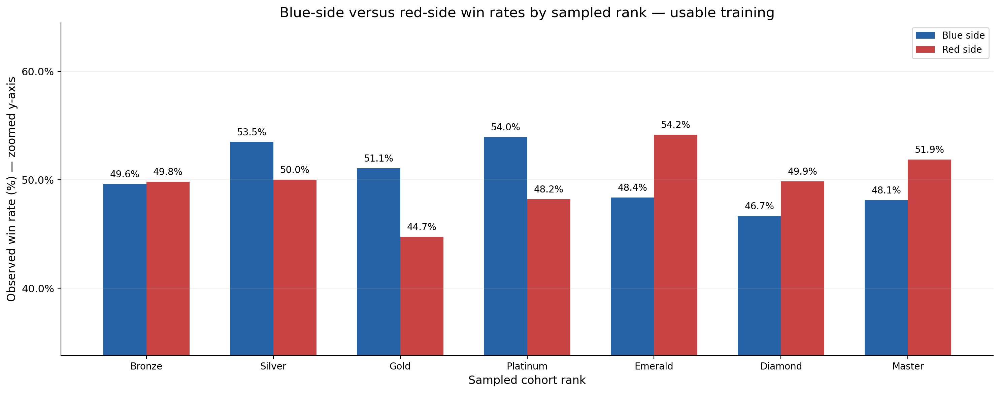

Rank,Side,Wins,Player-games,Distinct players,Win rate
Bronze,Blue,131,264,39,49.6%
Bronze,Red,137,275,41,49.8%
Silver,Blue,153,286,42,53.5%
Silver,Red,145,290,42,50.0%
Gold,Blue,144,282,41,51.1%
Gold,Red,115,257,40,44.7%
Platinum,Blue,232,430,40,54.0%
Platinum,Red,217,450,38,48.2%
Emerald,Blue,149,308,39,48.4%
Emerald,Red,176,325,43,54.2%


In [4]:
# Reuse the same verified usable training rows and team-to-side mapping.
for label,d in D.items():
    train=d['train']
    assert train.split.eq('train').all() and train.usable_data.all()
    assert train.team_id.isin([100,200]).all()
    assert train.side.eq(train.team_id.map({100:'blue',200:'red'})).all()
assert D['Bronze–Diamond']['train'].model_rank.isin(RANKS).all()
combined_rank_sides=pd.concat([
    D['Bronze–Diamond']['train'].assign(presentation_rank=lambda f:f.model_rank),
    D['Master-labeled']['train'].assign(presentation_rank='MASTER')],ignore_index=True)
combined_rank_order=RANKS+['MASTER']
combined_side_summaries={side:rate_summary(combined_rank_sides.loc[combined_rank_sides.side.eq(side)],
    'presentation_rank',combined_rank_order) for side in ['blue','red']}
combined_side_limits=percentage_limits(*(100*s[['observed','low','high']] for s in combined_side_summaries.values()))
fig,ax=plt.subplots(figsize=(15,6));x=np.arange(len(combined_rank_order));width=.34
for side,offset,color in [('blue',-width/2,COLORS['observed']),('red',width/2,COLORS['red'])]:
    summary=combined_side_summaries[side]
    errors=100*np.array([summary.observed-summary.low,summary.high-summary.observed])
    ax.bar(x+offset,100*summary.observed,width,color=color,label=side.title()+' side')
    for position,row in zip(x+offset,summary.itertuples()):
        ax.annotate(f'{100*row.observed:.1f}%',(position,100*row.observed),xytext=(0,5),
                    textcoords='offset points',ha='center',va='bottom',fontsize=10)
ax.set(xticks=x,xticklabels=[rank.title() for rank in combined_rank_order],xlabel='Sampled cohort rank',
       ylabel='Observed win rate (%) — zoomed y-axis',
       title='Blue-side versus red-side win rates by sampled rank — usable training')
set_rate_limits(ax,combined_side_limits)
ax.grid(axis='y',alpha=.2);ax.legend(loc='upper right');fig.tight_layout();plt.show()

combined_side_table=pd.concat(combined_side_summaries,names=['Side','Rank']).reorder_levels(['Rank','Side'])
combined_side_table=combined_side_table.reindex(pd.MultiIndex.from_product([combined_rank_order,['blue','red']],names=['Rank','Side']))
combined_side_table=combined_side_table.reset_index().rename(columns={
    'wins':'Wins','games':'Player-games','players':'Distinct players','observed':'Win rate'})
combined_side_table['Rank']=combined_side_table['Rank'].str.title()
combined_side_table['Side']=combined_side_table['Side'].str.title()
combined_side_table=combined_side_table[['Rank','Side','Wins','Player-games','Distinct players','Win rate']]
display(combined_side_table.style.hide(axis='index').format({
    'Wins':'{:,.0f}','Player-games':'{:,.0f}','Distinct players':'{:,.0f}','Win rate':'{:.1%}'}))

Ranks describe the sampled cohorts; Master uses **unverified legacy seed labels**. The y-axis is zoomed, with five percentage points of padding around the underlying approximate 95% Wilson bounds; error bars are omitted for clarity. Wilson intervals ignore repeated-player/shared-match dependence, and this chart does not establish a causal side or rank effect.

<a id="model-outline"></a>
## 4. Model outline and parameter estimates

“We estimate the probability of winning using matchup strength, recorded champion experience, historical champion win rate, history depth, role, and champion/player/player–champion adjustments. The broad model also adjusts for rank.”

$$
y_i\sim\operatorname{Bernoulli}(p_i),\qquad
\operatorname{logit}(p_i)=\alpha+\beta_m z_{m,i}+\beta_H z_{\log(1+H),i}+\beta_w z_{WR,i}
+\rho_{r(i)}+\delta_{q(i)}+a_{c(i)}+u_{j(i)}+v_{j(i),c(i)}
+b_{g(i)}\frac{n_i}{n_i+k}.
$$

**Shared:** one experience pattern across champions, $b_g=b$. **Grouped:** group-specific experience amplitudes, partially pooled across A–J/Unclassified: $b_g=b+\sigma_g(H_G z_g)_g$. Both use one common k within that model. The curve is **assumed to saturate**; the data estimate its amplitude and bend.

Master’s seed rank is constant and absorbed into its intercept, so its rank contrast is absent. Personalization uses learned player and player–champion adjustments; reference-player predictions set those adjustments to zero while retaining each choice’s recorded history and champion terms. They are not population averages.

In [15]:
variable_definitions=pd.DataFrame([
 ('pᵢ','Modeled probability of winning the focal player-game.'),
 ('z = (x − training mean) / training SD','Continuous predictors use the saved cohort-specific training centering/scaling.'),
 ('m','Raw LoLalytics matchup probability: Global exact tier for broad; Global Master+ for Master.'),
 ('H','Total strictly prior recorded all-role games; the fitted covariate is log(1+H).'),
 ('WR','Historical selected-champion WR with Beta(1,1) smoothing: (prior wins+1)/(prior games+2).'),
 ('ρ, δ','Role contrasts relative to top; broad rank contrasts relative to Bronze. Master rank is in its intercept.'),
 ('a꜀, uⱼ, vⱼ꜀','Champion baseline, player adjustment, and player–champion adjustment; partially pooled.'),
 ('n','Recorded prior champion games across all roles, bounded by collected season history—not lifetime experience.'),
 ('b or bɡ','Asymptotic experience amplitude in log-odds; grouped adds a zero-sum pooled group deviation.'),
 ('k','Recorded-game count where n/(n+k)=1/2: half the log-odds experience amplitude, not necessarily half a probability gain.'),
 ('α','Conditional intercept at standardized continuous predictors zero, n=0, reference role/rank, and zero random effects.')],columns=['Model term','Plain-language definition'])
display(variable_definitions.set_index('Model term'))


,Plain-language definition
Model term,
pᵢ,Modeled probability of winning the focal playe...
z = (x − training mean) / training SD,Continuous predictors use the saved cohort-spe...
m,Raw LoLalytics matchup probability: Global exa...
H,Total strictly prior recorded all-role games; ...
WR,"Historical selected-champion WR with Beta(1,1)..."
"ρ, δ",Role contrasts relative to top; broad rank con...
"a꜀, uⱼ, vⱼ꜀","Champion baseline, player adjustment, and play..."
n,Recorded prior champion games across all roles...
b or bɡ,Asymptotic experience amplitude in log-odds; g...


In [16]:
# Verify complete fit provenance/diagnostics before reading any cached draw array.
FITS={};prior_records=[];diagnostic_rows=[]
for label,d in D.items():
    source=d['model_source'];tree=ast.parse(source)
    model_node=next(node for node in tree.body if isinstance(node,ast.FunctionDef) and node.name=='pyro_model')
    model_text=ast.get_source_segment(source,model_node)+'\n'
    site_priors={}
    for node in ast.walk(model_node):
        if isinstance(node,ast.Call) and isinstance(node.func,ast.Name) and node.func.id=='normal':
            site=node.args[0].value
            loc=ast.get_source_segment(source,node.args[1]) if len(node.args)>1 else '0'
            scale=ast.get_source_segment(source,node.args[2]) if len(node.args)>2 else '1'
            for kw in node.keywords:
                if kw.arg=='loc':loc=ast.get_source_segment(source,kw.value)
                if kw.arg=='scale':scale=ast.get_source_segment(source,kw.value)
            site_priors[site]=(loc.replace('np.log','log'),scale)
    d['site_priors']=site_priors
    for specification in ['shared','grouped']:
        folder=d['path']/'fits'/specification
        manifest=json.loads(d['checked'](f'fits/{specification}/fit_manifest.json').read_text())
        status=json.loads(d['checked'](f'fits/{specification}/fit_status.json').read_text())
        diag=pd.read_csv(d['checked'](f'fits/{specification}/sampling_diagnostics.csv'))
        assert hashlib.sha256(model_text.encode()).hexdigest()==manifest['model_source_sha256']
        assert manifest['backend_version']=='1.9.2' and manifest['sampling']==dict(chains=4,draws=1200,warmup=600,max_tree_depth=9,train_match_limit=None)
        assert manifest['target_accept']==.9 and manifest['torch_threads']==1
        assert status['status']=='converged' and status['diagnostic_gate_passed']
        assert np.isfinite(diag[['rank_split_Rhat','bulk_ESS','tail_ESS']]).all().all()
        assert diag.rank_split_Rhat.max()<1.01 and diag.bulk_ESS.min()>400 and diag.tail_ESS.min()>400
        assert len(status['chains'])==4 and all(c['divergences']==0 and c['acceptance_rate']>=.8 for c in status['chains'])
        for i in range(4):
            info=json.loads(d['checked'](f'fits/{specification}/chain_{i}.json').read_text())
            archive=d['checked'](f'fits/{specification}/chain_{i}.npz')
            assert digest(archive)==info['samples_sha256'] and info==status['chains'][i]
        FITS[(label,specification)]=dict(manifest=manifest,status=status,diagnostic=diag)
        diagnostic_rows.append(dict(cohort=label,model=specification,chains=4,warmup_per_chain=600,draws_per_chain=1200,
            target_accept=.9,max_tree_depth=9,torch_threads=1,max_Rhat=diag.rank_split_Rhat.max(),
            min_bulk_ESS=diag.bulk_ESS.min(),min_tail_ESS=diag.tail_ESS.min(),divergences=0,min_acceptance=min(c['acceptance_rate'] for c in status['chains'])))
# Read only fixed/hyperparameter arrays, not thousands of individual identity coefficients.
for (label,specification),fit in FITS.items():
    keys=['alpha','beta','beta_role','beta_exp','log_k','log_sigma_player','log_sigma_pc','log_sigma_champion']
    if label=='Bronze–Diamond':keys+=['beta_rank']
    if specification=='grouped':keys+=['log_sigma_group','group_free']
    chains=[]
    for i in range(4):
        with np.load(D[label]['path']/'fits'/specification/f'chain_{i}.npz') as archive:
            assert label=='Bronze–Diamond' or 'beta_rank' not in archive.files
            values={key:archive[key] for key in keys}
        assert all(v.shape[0]==1200 and np.isfinite(v).all() for v in values.values());chains.append(values)
    fit['draws']={key:np.concatenate([chain[key] for chain in chains]) for key in keys}
    design=fit['manifest']['design']
    assert design['continuous']==['matchup_probability','log_total','historical_wr_beta11']
    np.testing.assert_allclose(D[label]['train'][design['continuous']].mean().to_numpy(),design['mean'],atol=1e-12)
    np.testing.assert_allclose(D[label]['train'][design['continuous']].std(ddof=0).to_numpy(),design['scale'],atol=1e-12)
    basis=np.array(design['group_basis']) if 'group_basis' in design else helmert(len(design['groups']),full=False).T
    # Broad's numeric matrix was not separately serialized: recover its exact
    # hash-verified fit-time Helmert definition using the saved group ordering.
    assert design['groups']==GROUPS and basis.shape==(11,10)
    np.testing.assert_allclose(basis.T@basis,np.eye(10),atol=1e-14)
    np.testing.assert_allclose(basis.sum(axis=0),0,atol=1e-14)
    fit['group_basis']=basis
print('All four completed fits and 16 chain archives verified. Cached draws loaded; no model or sampler was called.')


All four completed fits and 16 chain archives verified. Cached draws loaded; no model or sampler was called.


In [17]:
scaling_rows=[]
for label in D:
    design=FITS[(label,'shared')]['manifest']['design']
    for name,mean,scale,units in zip(['Raw matchup probability','log(1 + total prior games)','Historical champion WR Beta(1,1)'],
        design['mean'],design['scale'],['Probability (0–1)','Natural-log count units','Probability (0–1)']):
        scaling_rows.append(dict(cohort=label,predictor=name,training_mean=mean,training_SD=scale,raw_units=units))
scaling_table=pd.DataFrame(scaling_rows).set_index(['cohort','predictor'])
display(scaling_table.style.format({'training_mean':'{:.6f}','training_SD':'{:.6f}'}))

cached_parameter_rows=pd.read_csv(D['Master-labeled']['checked']('cohort_association_comparison.csv')).to_dict('records')
_cached_master=pd.read_csv(D['Master-labeled']['checked']('posterior_summary.csv'))
_cached_master['cohort']='Master-labeled';cached_parameter_rows+=_cached_master.to_dict('records')
CACHED_PARAMETERS={(r['cohort'],r['model'],r['quantity']):r for r in cached_parameter_rows}
PARAMETER_KEYS={'Matchup strength':'matchup_logodds_per_training_SD',
    'Matchup strength: common +2 raw pp':'matchup_logodds_per_2_raw_pp',
    'Common experience amplitude':'shared_experience_amplitude_logodds','Half-saturation count k':'k_recorded_games',
    'Player effect SD':'sigma_player','Player–champion effect SD':'sigma_pc','Champion contrast SD':'sigma_champion',
    'Group-deviation contrast SD':'sigma_group_contrast'}
print('Existing verified summary rows are reused where available; cached draws fill the remaining coefficients and sign probabilities.')

def parameter_summary(label,specification):
    fit=FITS[(label,specification)];s=fit['draws'];design=fit['manifest']['design'];rows=[]
    def add(name,values,units,positive=True):
        low,median,high=np.quantile(values,[.025,.5,.975])
        cached=CACHED_PARAMETERS.get((label,specification,PARAMETER_KEYS.get(name)))
        if cached is not None:
            np.testing.assert_allclose([low,median,high],[cached['low_95'],cached['median'],cached['high_95']],atol=1e-12)
            low,median,high=cached['low_95'],cached['median'],cached['high_95']
        rows.append({'Plain-language parameter':name,'Units / reference category':units,'Posterior median':median,
                     'Lower 95% credible limit':low,'Upper 95% credible limit':high,
                     'P(coefficient > 0)':float(np.mean(values>0)) if positive else np.nan})
    add('Intercept',s['alpha'],'Log-odds: centered continuous predictors, n=0, top role, reference rank, zero random effects')
    for j,(name,units) in enumerate([
        ('Matchup strength','Log-odds per 1 training SD of raw matchup probability'),
        ('Recorded history depth','Log-odds per 1 training SD of log(1 + total prior games)'),
        ('Historical champion WR','Log-odds per 1 training SD of historical Beta(1,1) WR')]):add(name,s['beta'][:,j],units)
    add('Matchup strength: common +2 raw pp',s['beta'][:,0]*.02/design['scale'][0],'Log-odds per +0.02 raw matchup probability; not win-probability pp')
    for j,role in enumerate(design['roles'][1:]):add(('ADC' if role=='adc' else role.title())+' role contrast',s['beta_role'][:,j],'Log-odds versus top')
    if 'beta_rank' in s:
        for j,rank in enumerate(design['ranks'][1:]):add(rank.title()+' rank contrast',s['beta_rank'][:,j],'Log-odds versus Bronze')
    add('Common experience amplitude',s['beta_exp'],'Asymptotic log-odds amplitude; shared b, or grouped zero-sum group mean')
    add('Half-saturation count k',np.exp(s['log_k']),'Recorded prior champion games',False)
    for key,name in [('log_sigma_player','Player effect SD'),('log_sigma_pc','Player–champion effect SD'),('log_sigma_champion','Champion contrast SD')]:
        add(name,np.exp(s[key]),'Log-odds scale; transformed from log SD',False)
    if specification=='grouped':add('Group-deviation contrast SD',np.exp(s['log_sigma_group']),'Log-odds amplitude scale; transformed from log SD',False)
    return pd.DataFrame(rows)

def show_parameter_table(table):
    numeric=['Posterior median','Lower 95% credible limit','Upper 95% credible limit']
    display(table.set_index('Plain-language parameter').style.format({**{c:'{:.3f}' for c in numeric},'P(coefficient > 0)':'{:.4f}'},na_rep='')
            .set_properties(subset=['Units / reference category'],**{'max-width':'270px','white-space':'normal','text-align':'left'}))

for label in D:
    display(Markdown('### '+label+' — primary shared model'))
    show_parameter_table(parameter_summary(label,'shared'))


Existing verified summary rows are reused where available; cached draws fill the remaining coefficients and sign probabilities.


### Bronze–Diamond — primary shared model

,Units / reference category,Posterior median,Lower 95% credible limit,Upper 95% credible limit,P(coefficient > 0)
Plain-language parameter,,,,,
Intercept,"Log-odds: centered continuous predictors, n=0, top role, reference rank, zero random effects",-0.170,-0.424,0.085,0.0902
Matchup strength,Log-odds per 1 training SD of raw matchup probability,0.173,0.101,0.246,1.0000
Recorded history depth,Log-odds per 1 training SD of log(1 + total prior games),-0.067,-0.138,0.006,0.0377
Historical champion WR,"Log-odds per 1 training SD of historical Beta(1,1) WR",0.025,-0.041,0.089,0.7675
Matchup strength: common +2 raw pp,Log-odds per +0.02 raw matchup probability; not win-probability pp,0.060,0.035,0.086,1.0000
Jungle role contrast,Log-odds versus top,0.051,-0.166,0.271,0.6810
Mid role contrast,Log-odds versus top,0.130,-0.091,0.337,0.8794
ADC role contrast,Log-odds versus top,0.065,-0.160,0.285,0.7219
Support role contrast,Log-odds versus top,0.161,-0.067,0.372,0.9213


### Master-labeled — primary shared model

,Units / reference category,Posterior median,Lower 95% credible limit,Upper 95% credible limit,P(coefficient > 0)
Plain-language parameter,,,,,
Intercept,"Log-odds: centered continuous predictors, n=0, top role, reference rank, zero random effects",-0.242,-0.498,-0.012,0.0196
Matchup strength,Log-odds per 1 training SD of raw matchup probability,0.333,0.265,0.407,1.0000
Recorded history depth,Log-odds per 1 training SD of log(1 + total prior games),-0.033,-0.093,0.030,0.1473
Historical champion WR,"Log-odds per 1 training SD of historical Beta(1,1) WR",0.013,-0.045,0.073,0.6640
Matchup strength: common +2 raw pp,Log-odds per +0.02 raw matchup probability; not win-probability pp,0.090,0.072,0.110,1.0000
Jungle role contrast,Log-odds versus top,0.045,-0.158,0.242,0.6642
Mid role contrast,Log-odds versus top,-0.181,-0.364,0.007,0.0292
ADC role contrast,Log-odds versus top,-0.063,-0.253,0.121,0.2673
Support role contrast,Log-odds versus top,-0.178,-0.390,0.036,0.0500


All displayed intervals are **95% Bayesian credible intervals**. Sign probabilities are posterior draw fractions, **not p-values**; no frequentist p-values are calculated. k and standard deviations have blank sign probabilities because positivity is imposed by their parameterization.

The primary experience amplitudes are positive: broad **.443 [.178, .780]** and Master **.458 [.232, .694] log-odds**. Master’s estimated bend is earlier (k **5.3 [1.5, 28.8]** versus broad **28.9 [7.5, 135.2]** games), but separate cohort fits do not establish faster learning or a rank effect. At a common +2 raw matchup percentage points, the fitted log-odds coefficients are **.060 [.035, .086]** broad and **.090 [.072, .110]** Master. These are not win-probability percentage-point gains; the logistic link and reference context matter.

<a id="model-findings"></a>
## 5. Saved model findings

Curves below are redrawn from the saved curve tables, not newly fitted or scored. Reference contexts are conditional slices, not population averages; the experience term controls for historical champion WR and the other model covariates.

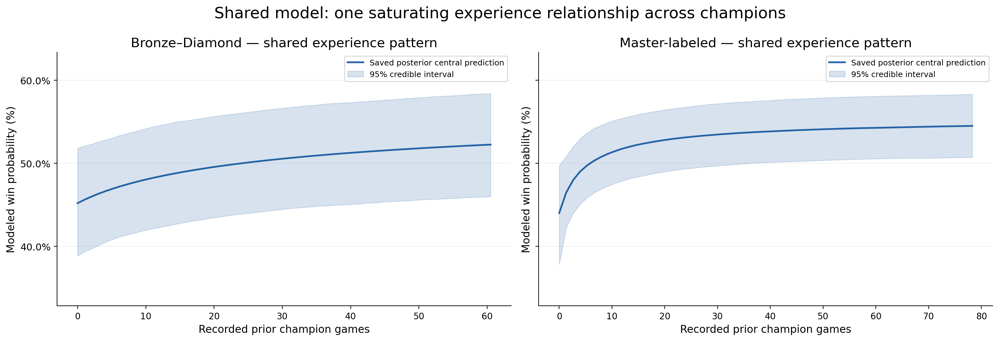

,role,rank_reference,raw_matchup_percent,historical_WR_percent,total_prior_games,displayed_experience_max,champion_player_PC_baselines
cohort,,,,,,,
Bronze–Diamond,Top,Bronze,50.46,51.09,175,60.50,All zero
Master-labeled,Top,Constant Master seed label,52.56,54.04,186,78.25,All zero


In [12]:
shared_display={}
for label,d in D.items():
    saved=d['curves'].loc[d['curves'].model.eq('shared')]
    caps=saved.groupby('group').n_recorded.max();floor=saved.groupby('group').n_recorded.min().max()
    limiting_group=caps.idxmin();f=saved.loc[saved.group.eq(limiting_group)&saved.n_recorded.ge(floor)].sort_values('n_recorded')
    shared_display[label]=f
shared_limits=percentage_limits(*(100*f[['mean' if 'mean' in f.columns else 'median','low','high']] for f in shared_display.values()))
fig,axes=plt.subplots(1,2,figsize=(16,5.5),sharey=True);curve_contexts=[]
for ax,(label,d) in zip(axes,D.items()):
    f=shared_display[label]
    central='mean' if 'mean' in f.columns else 'median'
    ax.plot(f.n_recorded,100*f[central],color=COLORS['observed'],lw=2,label='Saved posterior central prediction')
    ax.fill_between(f.n_recorded,100*f.low,100*f.high,color=COLORS['observed'],alpha=.18,label='95% credible interval')
    set_rate_limits(ax,shared_limits)
    ax.set(xlabel='Recorded prior champion games',ylabel='Modeled win probability (%)',title=label+' — shared experience pattern')
    ax.yaxis.set_major_formatter(PercentFormatter(100));ax.grid(axis='y',alpha=.2);ax.legend(fontsize=9)
    t=d['train'];curve_contexts.append(dict(cohort=label,role='Top',rank_reference='Bronze' if label=='Bronze–Diamond' else 'Constant Master seed label',
        raw_matchup_percent=100*t.matchup_probability.median(),historical_WR_percent=100*t.historical_wr_beta11.median(),
        total_prior_games=float(np.expm1(np.log1p(t.prior_total_games).median())),displayed_experience_max=f.n_recorded.max(),
        champion_player_PC_baselines='All zero'))
fig.suptitle('Shared model: one saturating experience relationship across champions',fontsize=18);fig.tight_layout();plt.show()
display(pd.DataFrame(curve_contexts).set_index('cohort').style.format({'raw_matchup_percent':'{:.2f}','historical_WR_percent':'{:.2f}','total_prior_games':'{:.0f}','displayed_experience_max':'{:.2f}'}))


Both fitted shared experience associations are positive, but the assumed saturation bend remains uncertain. These main panels conservatively stop at the smallest saved group-support cap (60.5 broad; 78.25 Master); the appendix includes the full saved supported ranges. Lines retain the saved summaries (broad posterior mean, Master posterior median) and cohort-specific contexts above. Different-looking curves do not establish a rank effect or a causal practice gain.

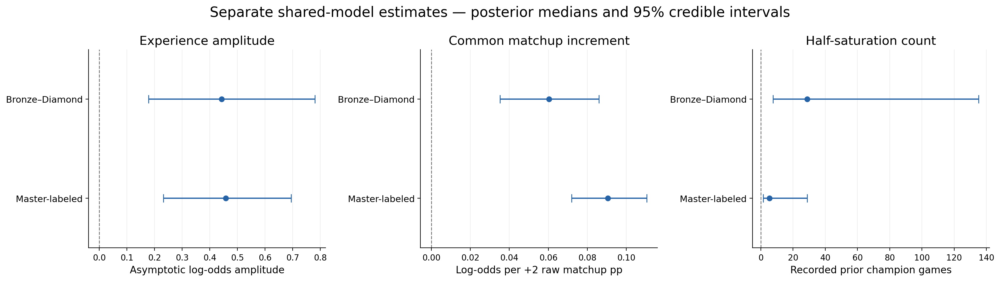

In [19]:
# This is the already saved cross-cohort posterior comparison, in common units.
association=pd.read_csv(D['Master-labeled']['checked']('cohort_association_comparison.csv'))
fig,axes=plt.subplots(1,3,figsize=(17,4.8));order=list(D)
for ax,quantity,title,xlabel in zip(axes,
    ['shared_experience_amplitude_logodds','matchup_logodds_per_2_raw_pp','k_recorded_games'],
    ['Experience amplitude','Common matchup increment','Half-saturation count'],
    ['Asymptotic log-odds amplitude','Log-odds per +2 raw matchup pp','Recorded prior champion games']):
    f=association.loc[association.model.eq('shared')&association.quantity.eq(quantity)].set_index('cohort').reindex(order)
    ax.errorbar(f['median'],np.arange(2),xerr=np.array([f['median']-f.low_95,f.high_95-f['median']]),fmt='o',capsize=5,color=COLORS['observed'])
    ax.axvline(0,color='#777777',ls='--',lw=1);ax.set(yticks=range(2),yticklabels=order,title=title,xlabel=xlabel)
    ax.set_ylim(-.5,1.5);ax.invert_yaxis();ax.grid(axis='x',alpha=.2)
fig.suptitle('Separate shared-model estimates — posterior medians and 95% credible intervals',fontsize=17);fig.tight_layout();plt.show()


The matchup comparison uses the same +2 raw probability-percentage-point increment, avoiding unequal training-SD units. These are separate conditional estimates; neither overlap nor differences in significance constitute a pooled rank-interaction test.

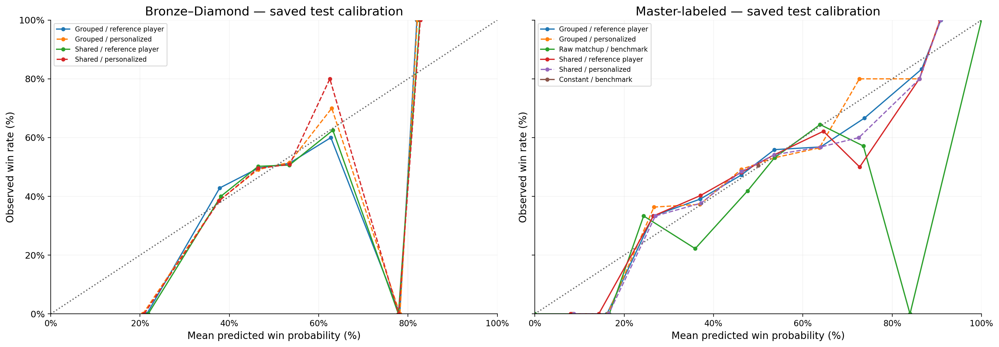

In [20]:
mode_names={'general':'reference player','personalized':'personalized','benchmark':'benchmark'}
model_names={'shared':'Shared','grouped':'Grouped','raw_matchup':'Raw matchup','training_prevalence':'Constant'}
fig,axes=plt.subplots(1,2,figsize=(17,6),sharex=True,sharey=True)
for ax,(label,d) in zip(axes,D.items()):
    calibration=d['calibration'].loc[d['calibration'].split.eq('test')]
    for (model,mode),f in calibration.groupby(['model','mode']):
        linestyle='--' if mode=='personalized' else '-'
        ax.plot(100*f.predicted,100*f.observed,'o',ls=linestyle,lw=1.5,ms=4,label=model_names[model]+' / '+mode_names[mode])
    ax.plot([0,100],[0,100],':',color='#666666');ax.set(xlim=(0,100),ylim=(0,100),xlabel='Mean predicted win probability (%)',
        ylabel='Observed win rate (%)',title=label+' — saved test calibration')
    ax.xaxis.set_major_formatter(PercentFormatter(100));ax.yaxis.set_major_formatter(PercentFormatter(100));ax.grid(alpha=.15)
    ax.legend(fontsize=8,loc='upper left')
fig.tight_layout();plt.show()


These are the existing held-out calibration bins, redrawn in percentage units without rescoring outcomes. Extreme bins have few games, so large bends there are unstable; Master includes saved simple-benchmark curves, while broad’s original saved calibration contains model curves only. All test outcomes were previously examined.

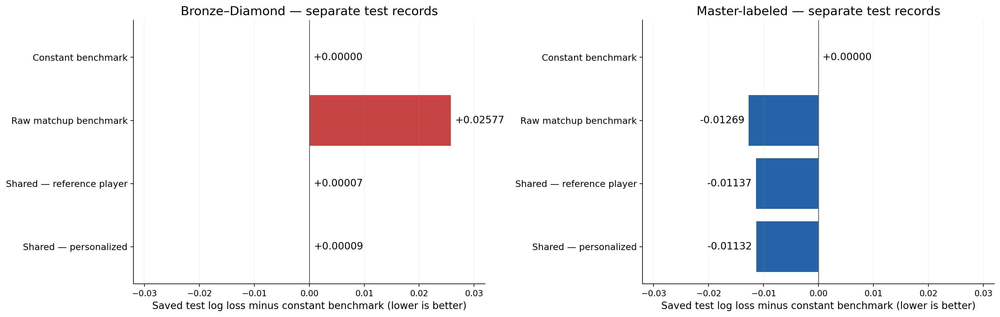

In [21]:
performance=pd.read_csv(D['Master-labeled']['checked']('cohort_performance_comparison.csv'))
method_order=[('training_prevalence','benchmark'),('raw_matchup','benchmark'),('shared','general'),('shared','personalized'),('grouped','general'),('grouped','personalized')]
def method_name(model,mode):return model_names[model]+(' benchmark' if mode=='benchmark' else ' — '+mode_names[mode])
fig,axes=plt.subplots(1,2,figsize=(17,5.5),sharex=True)
for ax,label in zip(axes,D):
    frame=performance.loc[performance.cohort.eq(label)&performance.split.eq('test')].set_index(['model','mode'])
    methods=method_order[:4];baseline=frame.loc[('training_prevalence','benchmark'),'log_loss']
    delta=np.array([frame.loc[key,'log_loss']-baseline for key in methods])
    ax.barh(range(4),delta,color=[COLORS['red'] if v>0 else COLORS['observed'] for v in delta])
    for i,v in enumerate(delta):ax.annotate(f'{v:+.5f}',(v,i),xytext=(5 if v>=0 else -5,0),textcoords='offset points',ha='left' if v>=0 else 'right',va='center')
    ax.axvline(0,color='#666666',lw=1);ax.set(yticks=range(4),yticklabels=[method_name(*key) for key in methods],
        xlabel='Saved test log loss minus constant benchmark (lower is better)',title=label+' — separate test records',xlim=(-.032,.032))
    ax.invert_yaxis();ax.grid(axis='x',alpha=.15)
fig.tight_layout();plt.show()
_test_rows=[]
for label in D:
    f=performance.loc[performance.cohort.eq(label)&performance.split.eq('test')].set_index(['model','mode']).reindex(method_order)
    for (model,mode),row in f.iterrows():_test_rows.append(dict(cohort=label,prediction=method_name(model,mode),player_games=int(row.rows),
        log_loss=row.log_loss,Brier=row.brier,AUC=row.roc_auc,equal_player_log_loss=row.equal_player_log_loss))
display(pd.DataFrame(_test_rows).set_index(['cohort','prediction']).style.format({'log_loss':'{:.5f}','Brier':'{:.5f}','AUC':'{:.4f}','equal_player_log_loss':'{:.5f}'}))


Master’s models beat the constant benchmark on game-weighted losses, but not its raw Master+ matchup benchmark. Broad model loss is close to the constant benchmark; raw exact-tier rates have worse log loss. This is arithmetic comparison of saved metrics, not new evaluation or a fresh test; it does not isolate experience’s predictive increment or establish prospective usefulness.

<a id="decisions"></a>
## 6. Main versus alternative — the central presentation section

Only **actual recorded-main picks** are included in these saved shared-model decision reports. Each eligible player-game appears once per prediction mode. The alternative is the familiar same-role champion with the highest saved posterior mean win probability among strictly better raw matchups; exact ties use smallest champion ID.

Reference-player mode uses the player’s recorded histories but zero learned player/player–champion adjustments. Personalization adds those learned adjustments (or pooled uncertainty for unseen identities). It is not a population-average comparison.

**Scope of these preserved results: familiar alternatives with prior same-role play. See the appended expanded-candidate section for the broader question.**

In [22]:
coverage_rows=[]
for label,d in D.items():
    f=d['summary'].loc[d['summary'].section.eq('coverage')]
    for row in f.itertuples():coverage_rows.append(dict(stage=row.measure,cohort=label,player_games=row.count,distinct_players=row.players,unique_matches=row.unique_matches))
coverage_frame=pd.DataFrame(coverage_rows)
stage_order=D['Master-labeled']['summary'].loc[lambda f:f.section.eq('coverage'),'measure'].tolist()
display(coverage_frame.pivot(index='stage',columns='cohort',values=['player_games','distinct_players','unique_matches']).reindex(stage_order))
losses=[]
for label,d in D.items():
    for row in d['summary'].loc[lambda f:f.section.eq('coverage_loss')].itertuples():losses.append(dict(reason=row.measure,cohort=label,player_games=row.count))
display(pd.DataFrame(losses).pivot(index='reason',columns='cohort',values='player_games'))


player_games  \
cohort                                             Bronze–Diamond   
stage                                                               
Retained chronological test player-games                      929   
Identifiable pregame main                                     929   
Actual main-pick games                                        288   
Main-pick games with usable main benchmark                    288   
Main-pick games with at least one eligible bett...            233   

                                                                   \
cohort                                             Master-labeled   
stage                                                               
Retained chronological test player-games                     1067   
Identifiable pregame main                                    1067   
Actual main-pick games                                        392   
Main-pick games with usable main benchmark                    392   
Main-pick games with at least one eligible bett...            324   

                                                   distinct_players  \
cohort                                               Bronze–Diamond   
stage                                                                 
Retained chronological test player-games                        152   
Identifiable pregame main                                       152   
Actual main-pick games                                           87   
Main-pick games with usable main benchmark                       87   
Main-pick games with at least one eligible bett...               77   

                                                                   \
cohort                                             Master-labeled   
stage                                                               
Retained chronological test player-games                      128   
Identifiable pregame main                                     128   
Actual main-pick games                                         91   
Main-pick games with usable main benchmark                     91   
Main-pick games with at least one eligible bett...             85   

                                                   unique_matches  \
cohort                                             Bronze–Diamond   
stage                                                               
Retained chronological test player-games                      926   
Identifiable pregame main                                     926   
Actual main-pick games                                        288   
Main-pick games with usable main benchmark                    288   
Main-pick games with at least one eligible bett...            233   

                                                                   
cohort                                             Master-labeled  
stage                                                              
Retained chronological test player-games                     1021  
Identifiable pregame main                                    1021  
Actual main-pick games                                        387  
Main-pick games with usable main benchmark                    387  
Main-pick games with at least one eligible bett...            321

cohort,Bronze–Diamond,Master-labeled
reason,,
Main history/features unusable,0,0
Main lacks prior same-role support required by saved main-reference comparisons,5,3
No recorded same-role alternative,5,18
No usable alternative with strictly better raw matchup,45,47
No usable same-role alternative benchmark/history,0,0


Master has **324 eligible games from 392 actual main picks**; broad has **233 from 288**. “Retained test” includes 1,067 Master / 929 broad chronological records, before the original scoring exclusions (1,065 / 928 scored rows); all actual main picks here have usable main benchmarks. Coverage losses include the saved main-reference requirement for prior same-role main support, missing familiar alternatives, or no strictly better usable matchup. Draft availability is unverified.

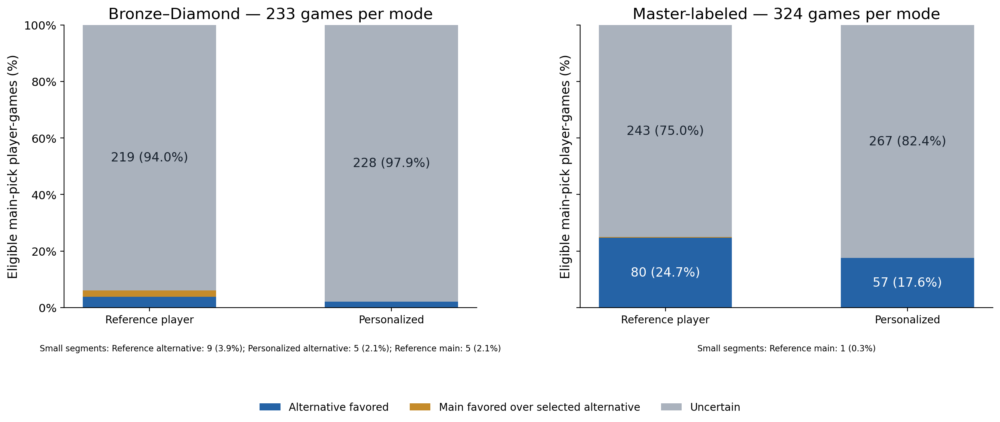

classification                  Alternative favored  \
cohort         mode                                   
Bronze–Diamond Personalized                5 (2.1%)   
               Reference player            9 (3.9%)   
Master-labeled Personalized              57 (17.6%)   
               Reference player          80 (24.7%)   

classification                  Main favored over selected alternative  \
cohort         mode                                                      
Bronze–Diamond Personalized                                   0 (0.0%)   
               Reference player                               5 (2.1%)   
Master-labeled Personalized                                   0 (0.0%)   
               Reference player                               1 (0.3%)   

classification                     Uncertain  
cohort         mode                           
Bronze–Diamond Personalized      228 (97.9%)  
               Reference player  219 (94.0%)  
Master-labeled Personalized      267 (82.4%)  
               Reference player  243 (75.0%)

In [23]:
fig,axes=plt.subplots(1,2,figsize=(16,6),sharey=True);class_colors=[COLORS['observed'],COLORS['benchmark'],COLORS['uncertain']]
classification_rows=[]
for ax,(label,d) in zip(axes,D.items()):
    summary=d['summary'];n_games=len(d['decisions'])//2;bottom=np.zeros(2);small=[]
    for category,color in zip(CLASSES,class_colors):
        f=summary.loc[summary.section.eq('classification')&summary.measure.eq(category)].set_index('mode').reindex(MODES)
        ax.bar(range(2),f.percent,bottom=bottom,color=color,width=.55,label=category)
        for i,row in enumerate(f.itertuples()):
            if row.percent>=5:ax.text(i,bottom[i]+row.percent/2,f'{row.count} ({row.percent:.1f}%)',ha='center',va='center',fontsize=12,color='white' if category==CLASSES[0] else '#17212D')
            elif row.count>0:small.append(('Reference' if i==0 else 'Personalized')+' '+('main' if category==CLASSES[1] else 'alternative')+f': {row.count} ({row.percent:.1f}%)')
            classification_rows.append(dict(cohort=label,mode=MODES[i],classification=category,games_and_percent=f'{row.count} ({row.percent:.1f}%)'))
        bottom+=f.percent.to_numpy()
    ax.set(xticks=range(2),xticklabels=['Reference player','Personalized'],ylim=(0,100),ylabel='Eligible main-pick player-games (%)',title=f'{label} — {n_games} games per mode')
    ax.yaxis.set_major_formatter(PercentFormatter(100))
    if small:ax.text(.5,-.13,'Small segments: '+'; '.join(small),transform=ax.transAxes,ha='center',va='top',fontsize=8,wrap=True)
fig.legend(*axes[0].get_legend_handles_labels(),loc='lower center',ncol=3,frameon=False,fontsize=10)
fig.subplots_adjust(bottom=.25,wspace=.25);plt.show()
display(pd.DataFrame(classification_rows).pivot(index=['cohort','mode'],columns='classification',values='games_and_percent').reindex(columns=CLASSES))


**Familiar-only results (prior same-role alternatives):**

Personalized selected alternatives are favored in **57/324 Master games (17.6%)** and **5/233 broad games (2.1%)**; most remain uncertain (82.4% / 97.9%). No personalized case favors main with a 95% interval wholly below zero. These are selected-comparison intervals—not simultaneous or selection-adjusted guarantees—and “main favored” refers only to that mode’s selected alternative.

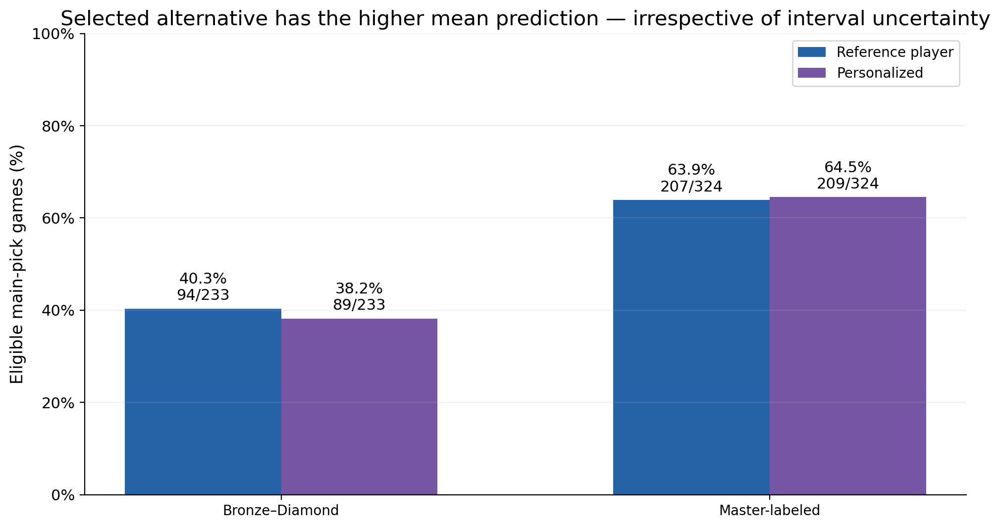

In [24]:
fig,ax=plt.subplots(figsize=(10,5.5));x=np.arange(len(D));width=.32
for mode,offset,color in [('Reference player',-width/2,COLORS['observed']),('Personalized',width/2,COLORS['personalized'])]:
    rows=[]
    for label,d in D.items():rows.append(d['summary'].loc[d['summary'].section.eq('point_preference')&d['summary']['mode'].eq(mode)].iloc[0])
    bars=ax.bar(x+offset,[r.percent for r in rows],width,color=color,label=mode)
    ax.bar_label(bars,labels=[f'{r.percent:.1f}%\n{r["count"]}/{r.denominator}' for r in rows],padding=4,fontsize=11)
ax.set(xticks=x,xticklabels=list(D),ylim=(0,100),ylabel='Eligible main-pick games (%)',title='Selected alternative has the higher mean prediction — irrespective of interval uncertainty')
ax.yaxis.set_major_formatter(PercentFormatter(100));ax.grid(axis='y',alpha=.2);ax.legend(loc='upper right');fig.tight_layout();plt.show()


The personalized mean prediction favors leaving main in **64.5%** of eligible Master games and **38.2%** of eligible broad games. A positive estimated difference is much more common than an interval excluding zero; it should not be presented as a confident recommendation or an observed switching gain.

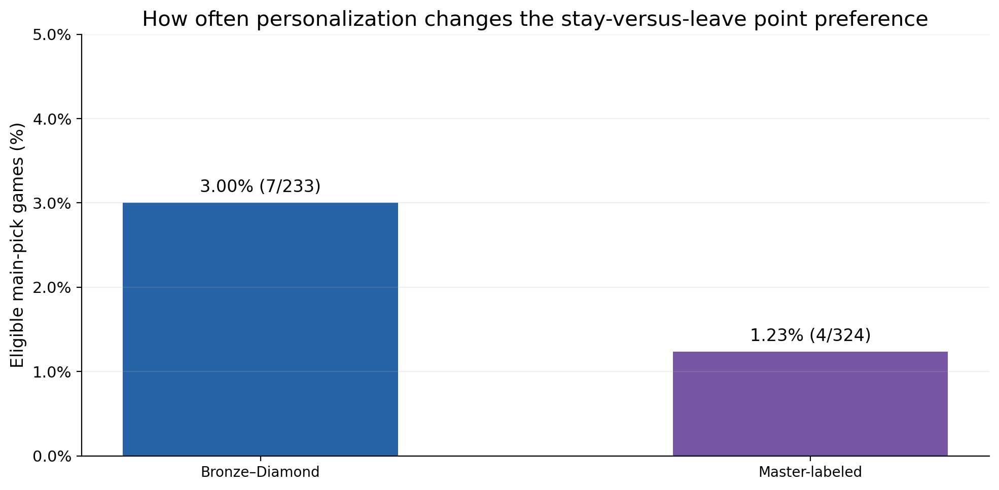

cohort,Bronze–Diamond,Master-labeled
change,,
Highest-mean choice champion changed,11 (4.72%),6 (1.85%)
Point preference switched between main and any alternative,7 (3.00%),4 (1.23%)
Selected alternative changed,8 (3.43%),3 (0.93%)
Uncertainty classification changed,9 (3.86%),24 (7.41%)


In [25]:
fig,ax=plt.subplots(figsize=(10,5));rows=[]
measure='Point preference switched between main and any alternative'
for label,d in D.items():rows.append(d['summary'].loc[d['summary'].section.eq('personalization_change')&d['summary'].measure.eq(measure)].iloc[0])
bars=ax.bar(list(D),[r.percent for r in rows],color=[COLORS['observed'],COLORS['personalized']],width=.5)
ax.bar_label(bars,labels=[f'{r.percent:.2f}% ({r["count"]}/{r.denominator})' for r in rows],padding=5,fontsize=12)
ax.set(ylim=(0,5),ylabel='Eligible main-pick games (%)',title='How often personalization changes the stay-versus-leave point preference')
ax.yaxis.set_major_formatter(PercentFormatter(100));ax.grid(axis='y',alpha=.2);fig.tight_layout();plt.show()
change_rows=[]
for label,d in D.items():
    for row in d['summary'].loc[lambda f:f.section.eq('personalization_change')].itertuples():change_rows.append(dict(change=row.measure,cohort=label,games_and_percent=f'{row.count} ({row.percent:.2f}%)'))
display(pd.DataFrame(change_rows).pivot(index='change',columns='cohort',values='games_and_percent'))


Personalization changes the stay/leave point preference in only **4/324 Master games (1.23%)** and **7/233 broad games (3.00%)**. Changing the best alternative, changing the highest-mean champion, and changing the uncertainty classification are separate quantities, shown in the table; none is evidence of realized gains from switching.

<a id="examples"></a>
## 7. Existing illustrative games — both modes side by side

Reuse the report’s chronological, distinct-game selection rule: the first alternative-favored, main-favored, then uncertain game in either mode, skipping games already shown. Each table names the mode(s) establishing its category. There are no personalized main-favored cases; the main-favored illustrations are explicitly reference-player only. Player labels are anonymous; champion names replace IDs.

In [26]:
# Only the existing pure example selector is reused; build_report is NOT called.
from hlr_model.main_pick_decision_report import example_rows
for label,d in D.items():
    display(Markdown('### '+label+' — saved actual-main-pick test games'))
    examples=example_rows(d['decisions'])
    assert len(examples[['puuid','match_id']].drop_duplicates())==3
    for category in CLASSES:
        f=examples.loc[examples.illustrative_category.eq(category)]
        if f.empty:print('No available example:',category);continue
        first=f.iloc[0]
        display(Markdown('**'+category+'** — '+first.anonymous_player+', '+str(pd.to_datetime(first.timestamp,unit='ms',utc=True))+', '+first.lane+
                         '. Category present in: **'+first.category_present_in_modes+'**.'))
        columns={}
        for row in f.itertuples():
            columns[row.mode]={
                'Main / selected alternative':row.main_champion+' / '+row.alternative_champion,
                'Prior champion games: main / alternative':f'{row.main_recorded_games:g} / {row.alternative_recorded_games:g}',
                'Historical WR: main / alternative':f'{row.main_historical_wr_beta11:.1%} / {row.alternative_historical_wr_beta11:.1%}',
                'Raw matchup: main / alternative':f'{row.main_raw_matchup_probability:.2%} / {row.alternative_raw_matchup_probability:.2%}',
                'Predicted win probability: main / alternative':f'{row.main_predicted_probability:.2%} / {row.alternative_probability:.2%}',
                'Alternative − main: pp [95% credible interval]':f'{row.difference_pp:+.2f} [{row.low_pp:+.2f}, {row.high_pp:+.2f}]',
                'Posterior probability alternative is higher':f'{row.probability_alternative_higher:.3f}',
                'Classification':row.classification,
                'Eligible better-matchup alternatives':row.eligible_alternatives,
                'Sparse training: main / alternative':f'{row.main_sparse_training_support} / {row.alternative_sparse_training_support}'}
        display(pd.DataFrame(columns).reindex(columns=MODES))


### Bronze–Diamond — saved actual-main-pick test games

**Alternative favored** — Player 001, 2026-10-05 01:43:55.190000+00:00, mid. Category present in: **Reference player**.

,Reference player,Personalized
Main / selected alternative,Akshan / Syndra,Akshan / Syndra
Prior champion games: main / alternative,82 / 1,82 / 1
Historical WR: main / alternative,54.8% / 33.3%,54.8% / 33.3%
Raw matchup: main / alternative,35.29% / 66.67%,35.29% / 66.67%
Predicted win probability: main / alternative,44.39% / 58.89%,44.83% / 58.48%
Alternative − main: pp [95% credible interval],"+14.50 [+1.21, +27.62]","+13.65 [-1.51, +28.79]"
Posterior probability alternative is higher,0.982,0.960
Classification,Alternative favored,Uncertain
Eligible better-matchup alternatives,11,11
Sparse training: main / alternative,True / True,True / True


**Main favored over selected alternative** — Player 149, 2026-10-05 16:19:15.113000+00:00, support. Category present in: **Reference player**.

,Reference player,Personalized
Main / selected alternative,Shaco / Pyke,Shaco / Pyke
Prior champion games: main / alternative,94 / 1,94 / 1
Historical WR: main / alternative,55.2% / 33.3%,55.2% / 33.3%
Raw matchup: main / alternative,51.58% / 52.00%,51.58% / 52.00%
Predicted win probability: main / alternative,60.01% / 50.37%,60.29% / 50.31%
Alternative − main: pp [95% credible interval],"-9.63 [-19.14, -1.05]","-9.97 [-22.07, +1.71]"
Posterior probability alternative is higher,0.015,0.047
Classification,Main favored over selected alternative,Uncertain
Eligible better-matchup alternatives,1,1
Sparse training: main / alternative,False / True,False / True


...

,Reference player,Personalized
Main / selected alternative,Caitlyn / Senna,Caitlyn / Senna
Prior champion games: main / alternative,114 / 24,114 / 24
Historical WR: main / alternative,51.7% / 53.8%,51.7% / 53.8%
Raw matchup: main / alternative,52.13% / 60.00%,52.13% / 60.00%
Predicted win probability: main / alternative,52.57% / 60.13%,52.20% / 59.83%
Alternative − main: pp [95% credible interval],"+7.55 [+0.99, +14.27]","+7.64 [-2.45, +18.12]"
Posterior probability alternative is higher,0.986,0.929
Classification,Alternative favored,Uncertain
Eligible better-matchup alternatives,3,3
Sparse training: main / alternative,False / True,False / True


**Main favored over selected alternative** — Player 107, 2026-10-07 03:19:52.249000+00:00, adc. Category present in: **Reference player**.

,Reference player,Personalized
Main / selected alternative,Draven / Twitch,Draven / Twitch
Prior champion games: main / alternative,272 / 1,272 / 1
Historical WR: main / alternative,54.4% / 33.3%,54.4% / 33.3%
Raw matchup: main / alternative,52.33% / 54.51%,52.33% / 54.51%
Predicted win probability: main / alternative,51.85% / 43.41%,49.37% / 41.00%
Alternative − main: pp [95% credible interval],"-8.44 [-16.63, -0.94]","-8.37 [-18.44, +2.08]"
Posterior probability alternative is higher,0.015,0.051
Classification,Main favored over selected alternative,Uncertain
Eligible better-matchup alternatives,1,1
Sparse training: main / alternative,False / True,False / True


**Uncertain** — Player 081, 2026-10-05 01:50:01.915000+00:00, mid. Category present in: **Personalized / Reference player**.

,Reference player,Personalized
Main / selected alternative,Zed / Vladimir,Zed / Vladimir
Prior champion games: main / alternative,105 / 6,105 / 6
Historical WR: main / alternative,52.3% / 50.0%,52.3% / 50.0%
Raw matchup: main / alternative,49.90% / 55.12%,49.90% / 55.12%
Predicted win probability: main / alternative,45.95% / 47.53%,44.68% / 46.70%
Alternative − main: pp [95% credible interval],"+1.58 [-5.21, +8.51]","+2.02 [-7.88, +12.13]"
Posterior probability alternative is higher,0.687,0.652
Classification,Uncertain,Uncertain
Eligible better-matchup alternatives,3,3
Sparse training: main / alternative,False / True,False / True


These are illustrative selected comparisons, not realized results for the unplayed alternative. Each choice retains its own history and benchmark; selecting the highest mean does not adjust its paired interval for selection or verify draft availability.

<a id="appendix"></a>
## 8. Appendix — cleaner EDA and secondary model details

### 8.1 Cleaner copies without Wilson intervals

These copies use exactly the same matched training rows, categories, observed WR and benchmark means as the main EDA. They remove interval bars for presentation clarity, not because uncertainty has disappeared.

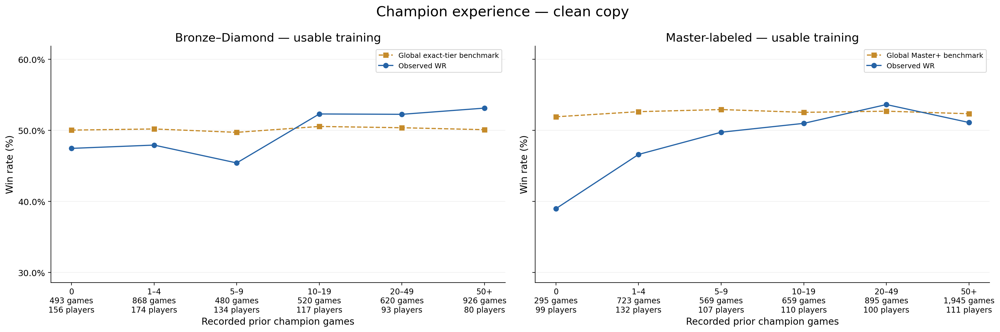

In [13]:
paired_rates('experience_bin',EXPERIENCE,'Champion experience — clean copy','Recorded prior champion games',intervals=False)

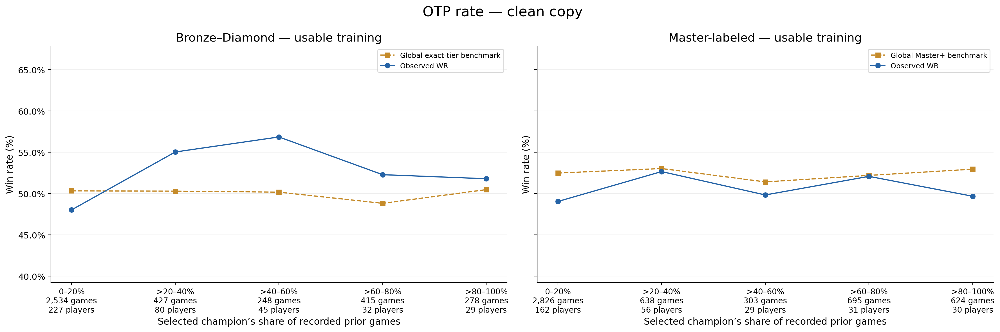

In [14]:
paired_rates('usage_bin',USAGE,'OTP rate — clean copy','Selected champion’s share of recorded prior games',intervals=False)

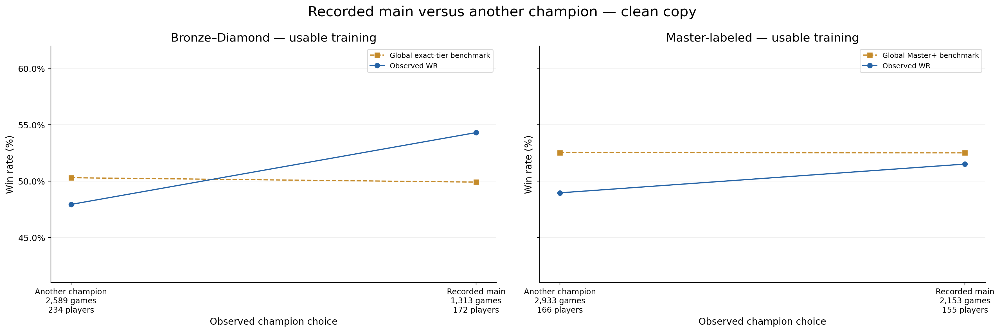

In [15]:
paired_rates('main_choice',['Another champion','Recorded main'],'Recorded main versus another champion — clean copy','Observed champion choice',intervals=False)

The clean copies retain the same zoomed percentage limits as their with-interval counterparts, including Wilson bounds when calculating the range, and identical category alignment. Use the main versions when discussing uncertainty; no new outcomes or benchmarks enter these copies.

### 8.2 Full saved shared/grouped curve ranges

The shared model has one experience term across champions; the grouped model allows its amplitude to differ across A–J/Unclassified with partial pooling. Grouped is secondary. Both assume saturation, and groups are not constrained to follow workbook order.

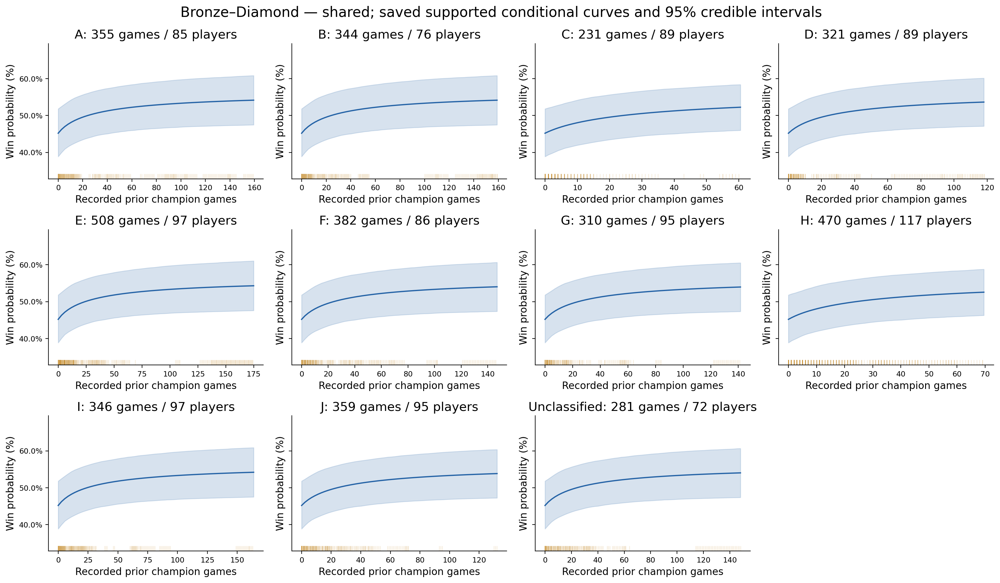

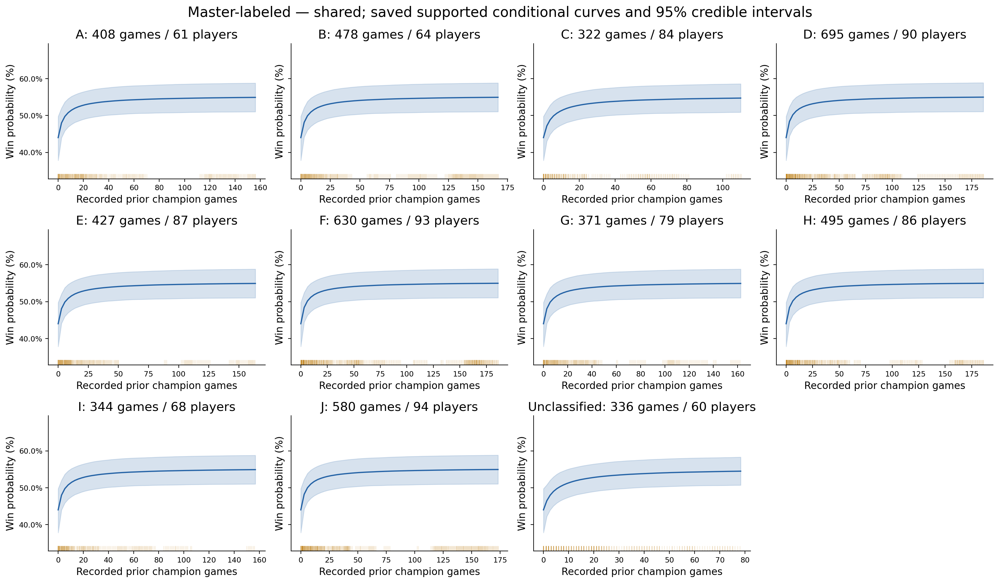

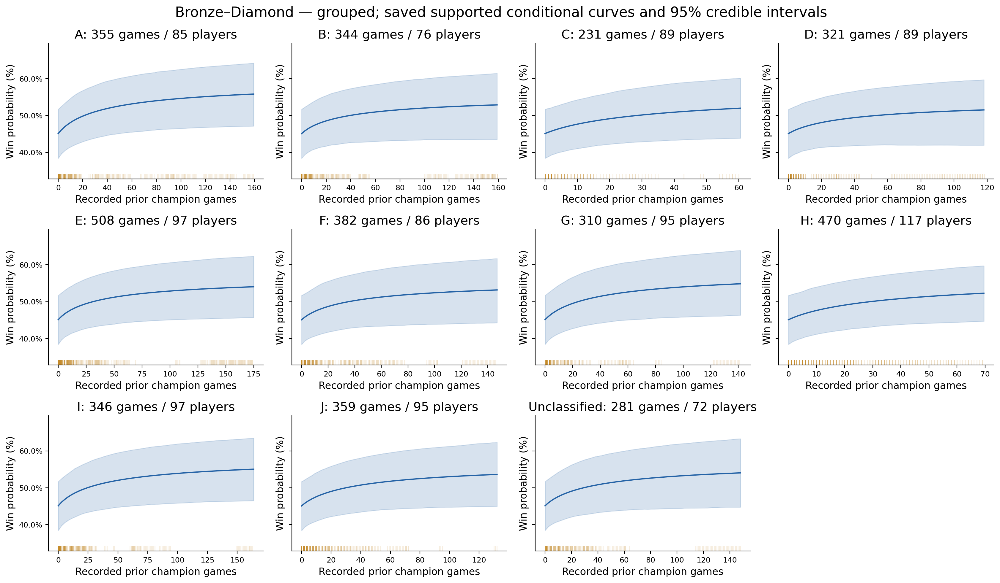

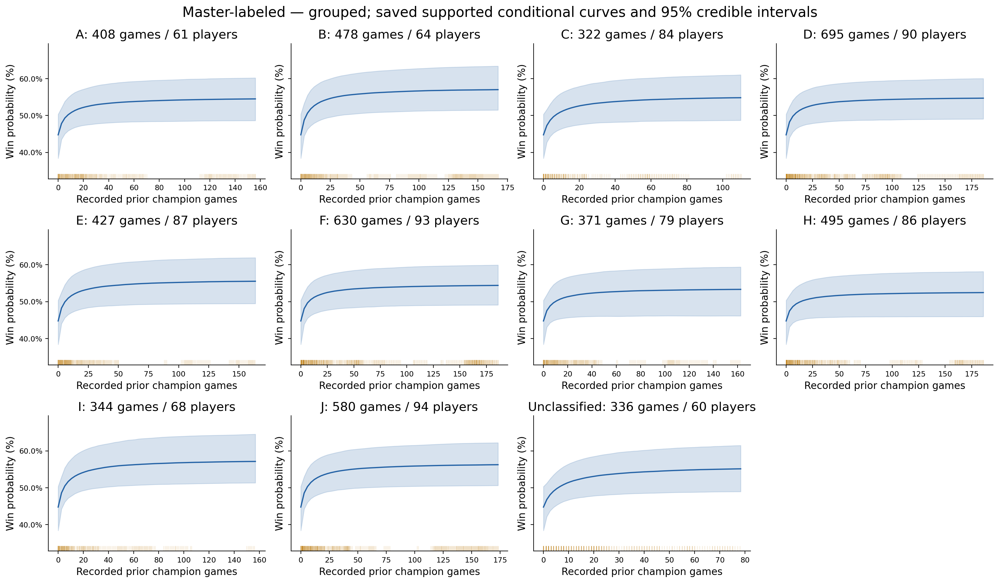

In [16]:
# One range across both cohorts/specifications and every displayed group band.
appendix_curve_limits=percentage_limits(*(100*d['curves'].loc[d['curves'].model.isin(['shared','grouped']),
    ['mean' if 'mean' in d['curves'].columns else 'median','low','high']] for d in D.values()))
for specification in ['shared','grouped']:
    for label,d in D.items():
        saved=d['curves'].loc[d['curves'].model.eq(specification)]
        fig,axes=plt.subplots(3,4,figsize=(17,10),sharey=True)
        for j,group in enumerate(GROUPS):
            ax=axes.flat[j];f=saved.loc[saved.group.eq(group)].sort_values('n_recorded')
            if f.empty:ax.set(title=group+' — no saved supported curve');ax.axis('off');continue
            central='mean' if 'mean' in f.columns else 'median'
            ax.plot(f.n_recorded,100*f[central],color=COLORS['observed'])
            ax.fill_between(f.n_recorded,100*f.low,100*f.high,color=COLORS['observed'],alpha=.18)
            support=d['train'].loc[d['train'].mastery_group.eq(group)]
            rug=support.loc[support.n_recorded.between(f.n_recorded.min(),f.n_recorded.max()),'n_recorded']
            ax.plot(rug,np.full(len(rug),.02),'|',transform=ax.get_xaxis_transform(),alpha=.15,color=COLORS['benchmark'])
            set_rate_limits(ax,appendix_curve_limits)
            ax.set(title=f'{group}: {int(f.training_games.iloc[0])} games / {int(f.training_players.iloc[0])} players',
                   xlabel='Recorded prior champion games',ylabel='Win probability (%)')
            ax.yaxis.set_major_formatter(PercentFormatter(100));ax.tick_params(labelsize=9)
        axes.flat[-1].axis('off');fig.suptitle(label+' — '+specification+'; saved supported conditional curves and 95% credible intervals',fontsize=17)
        fig.tight_layout();plt.show()


All four shared/grouped curve grids share one zoomed probability range, including every displayed credible band. Every panel stops at its original saved group support/context cap; rugs show actual training observations inside that range. Broad lines are saved posterior means and Master lines saved medians; all bands are pointwise 95% credible intervals. Sparse players at high experience limit interpretation, and these are conditional associations rather than causal learning curves.

### 8.3 Grouped-model parameter estimates and total group amplitudes

The following secondary tables use the same units and 95% credible-interval definitions as the primary tables. Individual player/champion coefficients are summarized through their scales rather than listed.

In [31]:
for label in D:
    display(Markdown('#### '+label+' — secondary grouped model'))
    show_parameter_table(parameter_summary(label,'grouped'))
    fit=FITS[(label,'grouped')];s=fit['draws']
    deviations=np.exp(s['log_sigma_group'])[:,None]*(s['group_free']@fit['group_basis'].T)
    np.testing.assert_allclose(deviations.sum(axis=1),0,atol=1e-12)
    total=s['beta_exp'][:,None]+deviations
    group_rows=[]
    for j,group in enumerate(GROUPS):
        low,median,high=np.quantile(total[:,j],[.025,.5,.975])
        group_rows.append({'Group':group,'Posterior median':median,'Lower 95% credible limit':low,'Upper 95% credible limit':high,'P(total amplitude > 0)':np.mean(total[:,j]>0)})
    group_table=pd.DataFrame(group_rows).set_index('Group')
    if label=='Master-labeled':
        cached=pd.read_csv(d['checked']('group_amplitude_summary.csv')).set_index('quantity').reindex(GROUPS)
        np.testing.assert_allclose(group_table[['Posterior median','Lower 95% credible limit','Upper 95% credible limit']].to_numpy(),cached[['median','low_95','high_95']].to_numpy(),atol=1e-12)
    display(Markdown('**Actual total group experience amplitudes (log-odds), not contrast coordinates.**'))
    display(group_table.style.format({c:'{:.3f}' for c in group_table.columns if not c.startswith('P(')}|{'P(total amplitude > 0)':'{:.4f}'}))


#### Bronze–Diamond — secondary grouped model

,Units / reference category,Posterior median,Lower 95% credible limit,Upper 95% credible limit,P(coefficient > 0)
Plain-language parameter,,,,,
Intercept,"Log-odds: centered continuous predictors, n=0, top role, reference rank, zero random effects",-0.172,-0.440,0.087,0.0954
Matchup strength,Log-odds per 1 training SD of raw matchup probability,0.173,0.101,0.249,1.0000
Recorded history depth,Log-odds per 1 training SD of log(1 + total prior games),-0.067,-0.138,0.005,0.0346
Historical champion WR,"Log-odds per 1 training SD of historical Beta(1,1) WR",0.025,-0.040,0.091,0.7712
Matchup strength: common +2 raw pp,Log-odds per +0.02 raw matchup probability; not win-probability pp,0.060,0.035,0.087,1.0000
Jungle role contrast,Log-odds versus top,0.057,-0.160,0.278,0.6937
Mid role contrast,Log-odds versus top,0.142,-0.076,0.357,0.8965
ADC role contrast,Log-odds versus top,0.076,-0.153,0.302,0.7504
Support role contrast,Log-odds versus top,0.161,-0.068,0.385,0.9165


**Actual total group experience amplitudes (log-odds), not contrast coordinates.**

,Posterior median,Lower 95% credible limit,Upper 95% credible limit,P(total amplitude > 0)
Group,,,,
A,0.555,0.182,1.136,0.9977
B,0.407,-0.021,0.914,0.9715
C,0.474,0.025,1.091,0.9794
D,0.365,-0.095,0.922,0.9413
E,0.458,0.092,0.966,0.9929
F,0.432,0.040,0.960,0.9838
G,0.513,0.128,1.111,0.9946
H,0.472,0.079,1.076,0.9904
I,0.512,0.117,1.084,0.9942


#### Master-labeled — secondary grouped model

,Units / reference category,Posterior median,Lower 95% credible limit,Upper 95% credible limit,P(coefficient > 0)
Plain-language parameter,,,,,
Intercept,"Log-odds: centered continuous predictors, n=0, top role, reference rank, zero random effects",-0.212,-0.475,0.011,0.0321
Matchup strength,Log-odds per 1 training SD of raw matchup probability,0.335,0.266,0.403,1.0000
Recorded history depth,Log-odds per 1 training SD of log(1 + total prior games),-0.032,-0.096,0.028,0.1608
Historical champion WR,"Log-odds per 1 training SD of historical Beta(1,1) WR",0.015,-0.045,0.072,0.6890
Matchup strength: common +2 raw pp,Log-odds per +0.02 raw matchup probability; not win-probability pp,0.091,0.072,0.109,1.0000
Jungle role contrast,Log-odds versus top,0.035,-0.163,0.235,0.6352
Mid role contrast,Log-odds versus top,-0.176,-0.367,0.008,0.0327
ADC role contrast,Log-odds versus top,-0.064,-0.249,0.134,0.2504
Support role contrast,Log-odds versus top,-0.179,-0.389,0.040,0.0504


**Actual total group experience amplitudes (log-odds), not contrast coordinates.**

,Posterior median,Lower 95% credible limit,Upper 95% credible limit,P(total amplitude > 0)
Group,,,,
A,0.421,0.100,0.723,0.9925
B,0.531,0.243,0.832,0.9998
C,0.446,0.132,0.770,0.9962
D,0.426,0.114,0.706,0.9956
E,0.467,0.150,0.782,0.9985
F,0.415,0.131,0.686,0.9975
G,0.371,-0.003,0.675,0.9738
H,0.327,-0.007,0.630,0.9733
I,0.539,0.235,0.880,0.9998


These totals add the shared amplitude to the corresponding reconstructed zero-sum group deviation. Sign probabilities are posterior probabilities, not p-values; marginal-interval overlap alone is not a formal group comparison. No fitted A–J ordering or formal cross-cohort rank interaction is claimed.

### 8.4 Priors extracted from the fitted implementation

In [32]:
prior_labels={
 'alpha':('Intercept','Log-odds'), 'beta':('All standardized continuous coefficients','Log-odds per training SD'),
 'beta_role':('Role contrasts','Log-odds versus top'), 'beta_rank':('Broad rank contrasts','Log-odds versus Bronze'),
 'beta_exp':('Common experience amplitude','Asymptotic log-odds'), 'log_k':('log(k)','Natural log of recorded-game count'),
 'log_sigma_player':('log(player SD)','Log of a log-odds SD'), 'log_sigma_pc':('log(player–champion SD)','Log of a log-odds SD'),
 'log_sigma_champion':('log(champion contrast SD)','Log of a log-odds contrast SD'),
 'log_sigma_group':('log(group-deviation contrast SD)','Log of a log-odds amplitude SD'),
 'player_z':('Standardized player latents','Dimensionless, multiplied by player SD'),
 'pc_z':('Standardized player–champion latents','Dimensionless, multiplied by PC SD'),
 'champion_free':('Standardized champion contrasts','Dimensionless, multiplied by champion SD/basis'),
 'group_free':('Standardized group contrasts','Dimensionless, multiplied by group SD/basis')}
prior_rows=[]
for site,(name,units) in prior_labels.items():
    available=[(label,d['site_priors'][site]) for label,d in D.items() if site in d['site_priors']]
    assert available
    expressions={tuple(expr) for _,expr in available};assert len(expressions)==1
    loc,scale=next(iter(expressions))
    applicability='Grouped only, both cohorts' if site in ['log_sigma_group','group_free'] else 'Broad only, shared/grouped' if site=='beta_rank' else 'Both cohorts, shared/grouped'
    prior_rows.append({'Parameter / latent block':name,'Actual fitted prior':f'Normal({loc}, {scale})','Units':units,'Applies to':applicability})
display(pd.DataFrame(prior_rows).set_index('Parameter / latent block'))


,Actual fitted prior,Units,Applies to
Parameter / latent block,,,
Intercept,"Normal(0, 2.)",Log-odds,"Both cohorts, shared/grouped"
All standardized continuous coefficients,"Normal(0, 2.)",Log-odds per training SD,"Both cohorts, shared/grouped"
Role contrasts,"Normal(0, 1)",Log-odds versus top,"Both cohorts, shared/grouped"
Broad rank contrasts,"Normal(0, 1)",Log-odds versus Bronze,"Broad only, shared/grouped"
Common experience amplitude,"Normal(0, 1)",Asymptotic log-odds,"Both cohorts, shared/grouped"
log(k),"Normal(log(30), 1.)",Natural log of recorded-game count,"Both cohorts, shared/grouped"
log(player SD),"Normal(log(.3), .7)",Log of a log-odds SD,"Both cohorts, shared/grouped"
log(player–champion SD),"Normal(log(.15), .5)",Log of a log-odds SD,"Both cohorts, shared/grouped"
log(champion contrast SD),"Normal(log(.3), .7)",Log of a log-odds contrast SD,"Both cohorts, shared/grouped"


Normal’s second argument is the prior standard deviation. Log-scale priors imply positive k/scales after exponentiation; noncentered identity/contrast latents have standard-Normal priors. Champion and group effects use orthonormal zero-sum contrasts, so a level’s conditional marginal SD is its contrast scale × √(1−1/L), with L levels. Priors above were extracted from the hash-verified model source, not inferred from posterior draws.

### 8.5 Sampling, convergence, reference categories and training support

In [33]:
settings=pd.DataFrame([
 ('Backend','Pyro 1.9.2, exact Bernoulli NUTS'),('Chains','4 sequential chains per model'),
 ('Warmup per chain',600),('Retained draws per chain',1200),('Target acceptance',.9),('Maximum tree depth',9),('Torch threads',1),
 ('Diagnostic gate','Finite rank/folded split R-hat <1.01; bulk/tail ESS >400; zero divergences; chain acceptance ≥.8'),
 ('Unavailable diagnostics','Tree-depth saturation and BFMI')],columns=['Setting','Saved completed fit'])
display(settings.set_index('Setting'))
diagnostic_table=pd.DataFrame(diagnostic_rows).set_index(['cohort','model'])
display(diagnostic_table[['max_Rhat','min_bulk_ESS','min_tail_ESS','divergences','min_acceptance']].style.format(
    {'max_Rhat':'{:.5f}','min_bulk_ESS':'{:.0f}','min_tail_ESS':'{:.0f}','min_acceptance':'{:.2f}'}))
reference_table=pd.DataFrame([
 ('Role','Top for both cohorts'),('Rank','Bronze in broad; constant Master seed label absorbed in Master intercept'),
 ('Continuous predictors','Each cohort’s saved training means and SDs; zero standardized value means the training mean'),
 ('Champion baseline','Zero-sum, regularized champion effects; no single champion reference category'),
 ('Reference-player prediction','Zero player/PC adjustments; own recorded history and champion baseline retained'),
 ('Saved curve context','Additionally zero champion baseline; top role, reference rank and cohort training-median continuous features'),
 ('Personalized prediction','Training-conditioned identity effects; unseen identities use fitted pooled distributions with uncertainty')],columns=['Quantity','Reference / interpretation'])
display(reference_table.set_index('Quantity'))
training_support=pd.read_csv(D['Master-labeled']['checked']('cohort_support_comparison.csv'))
display(training_support.set_index('cohort').style.format({'fraction_pc_once':'{:.1%}','fraction_pc_lt5':'{:.1%}'}))


,Saved completed fit
Setting,
Backend,"Pyro 1.9.2, exact Bernoulli NUTS"
Chains,4 sequential chains per model
Warmup per chain,600
Retained draws per chain,1200
Target acceptance,0.9
Maximum tree depth,9
Torch threads,1
Diagnostic gate,Finite rank/folded split R-hat <1.01; bulk/tai...
Unavailable diagnostics,Tree-depth saturation and BFMI


,Reference / interpretation
Quantity,
Role,Top for both cohorts
Rank,Bronze in broad; constant Master seed label ab...
Continuous predictors,Each cohort’s saved training means and SDs; ze...
Champion baseline,"Zero-sum, regularized champion effects; no sin..."
Reference-player prediction,Zero player/PC adjustments; own recorded histo...
Saved curve context,"Additionally zero champion baseline; top role,..."
Personalized prediction,Training-conditioned identity effects; unseen ...


,training_rows,players,matches,pc_pairs,median_games_per_pc,fraction_pc_once,fraction_pc_lt5,players_n_ge100
cohort,,,,,,,,
Bronze–Diamond,3907,265,3892,1417,1.000000,59.4%,87.8%,37
Master-labeled,5086,177,4746,1388,1.000000,55.5%,82.9%,65


Both full fits passed their saved gates, which supports stable numerical sampling under these models. It does not guarantee good out-of-sample discrimination or reliable pick advice. Median likelihood support is only one training game per player–champion pair in both cohorts; one training appearance is not a first-ever pick, because recorded season-history games are separate feature data.

<a id="limitations"></a>
## 9. Limitations and figures to use with David

- These are observational comparisons. There is no observed outcome for an unplayed alternative and no established causal gain from practice or switching.
- Pick order is missing and draft availability is unverified; “eligible” means eligible under recorded-history rules only. Role labels are inferred from completed play, not verified pregame intent.
- Player–champion likelihood support is sparse despite sometimes long prior histories. Repeated players/shared matches also limit simple independent-row uncertainty summaries.
- External rates cover the full patch and may overlap evaluated games; benchmark uncertainty and study transport error are outside the conditional posterior intervals.
- Validation/test outcomes were previously examined. Staged scoring did not restore a fresh confirmatory test.
- Master rank labels are undated/unverified; its benchmark is Global Master+, while broad uses exact tiers and collection-time rank labels.
- Separate cohort fits are not a formal pooled rank-interaction analysis. There are 31 shared matches across cohorts; no pooling is performed here.
- Highest-mean alternative selection does not make its paired interval selection-adjusted. “Main favored” concerns the selected alternative, and reference-player predictions are not population averages.

**Strongest figures for David:**

1. **Section 6 — interval-based selected-alternative classifications:** the central answer, with uncertainty kept visible.
2. **Section 6 — higher mean prediction:** distinguishes a point preference from an interval-supported preference.
3. **Section 6 — personalization’s stay/leave changes:** only 4/324 Master and 7/233 broad eligible games change that point decision.
4. **Section 2 — recorded experience versus observed/benchmark WR:** descriptive context, with matched rows and Wilson intervals.
5. **Section 5 — shared experience curves:** the fitted conditional association and uncertain saturation shape.
6. **Section 5 — performance against fixed benchmarks:** stable sampling did not establish a reliable recommendation tool.
7. **Section 5 — common-unit association comparison:** makes experience/matchup estimates comparable without pretending it tests rank differences.

All requested chart families are supported by the saved inputs; no side or history figure was omitted. Clean EDA, full shared/grouped curves, grouped parameter tables, actual priors and diagnostic/reference details are in Section 8. Figures and tables are rendered inline; no additional export files are created.

**Familiar-only tables below:** the preserved 17.6% Master / 2.1% broad interval-favored findings use alternatives previously played in the same role. Expanded results are in Section 10.

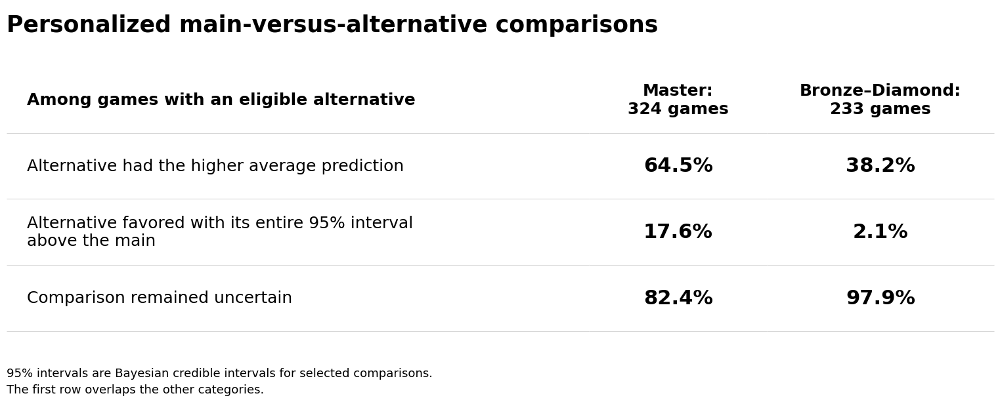

In [1]:
# Read-only game-level reporting; this cell can also run independently.
from pathlib import Path
import hashlib, json, textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

_here=Path.cwd().resolve()
_table_root=next(p for p in [_here,*_here.parents] if (p/'hlr_model/main_pick_decision_report.py').is_file())
_table_sources=[('Master',324,'master_cohort_mastery_v1/20261028T214327398991Z_4beeb7d4'),
                ('Bronze–Diamond',233,'broad_rank_mastery_v1/20261028T193830350096Z_5a469939')]
_table_measures=[('point_preference','Alternative has strictly higher mean prediction'),
                 ('classification','Alternative favored'),('classification','Uncertain')]
personalized_presentation_values=[]
for cohort,denominator,version in _table_sources:
    source=_table_root/'hlr_model/data/analyses'/version
    report=source/'reports/main_pick_decisions_v1'
    decisions=pd.read_parquet(report/'game_level_decisions.parquet')
    provenance=decisions.attrs['provenance']
    assert provenance['source_version']==source.name
    assert hashlib.sha256((_table_root/'hlr_model/main_pick_decision_report.py').read_bytes()).hexdigest()==provenance['report_helper_sha256']
    for name in ['prepared_played.parquet','paired_recommendations.parquet','fits/shared/fit_manifest.json']:
        assert hashlib.sha256((source/name).read_bytes()).hexdigest()==provenance['input_sha256'][name]
    assert json.loads((source/'fits/shared/fit_manifest.json').read_text())['model']=='shared'
    personal=decisions.loc[decisions['mode'].eq('Personalized')]
    assert len(personal)==denominator and not personal.duplicated(['puuid','match_id']).any()
    assert personal.eligible_alternatives.gt(0).all()
    assert personal.alternative_raw_matchup_probability.gt(personal.main_raw_matchup_probability).all()
    actual=pd.read_parquet(source/'prepared_played.parquet',columns=['puuid','match_id','champion_id','prior_main_champion_id'],filters=[('split','==','test')])
    matched=personal.merge(actual,on=['puuid','match_id'],validate='one_to_one')
    assert len(matched)==denominator and matched.champion_id.eq(matched.prior_main_champion_id).all()
    assert matched.main_champion_id.eq(matched.champion_id).all()
    summary=pd.read_csv(report/'summary.csv')
    counts=[int(personal.alternative_has_higher_mean.sum()),int(personal.low_pp.gt(0).sum()),
            int((personal.low_pp.le(0)&personal.high_pp.ge(0)).sum())]
    values=[]
    for (section,measure),count in zip(_table_measures,counts):
        row=summary.loc[summary['mode'].eq('Personalized')&summary.section.eq(section)&summary.measure.eq(measure)]
        assert len(row)==1 and int(row.iloc[0]['count'])==count and int(row.iloc[0].denominator)==denominator
        np.testing.assert_allclose(row.iloc[0].percent,100*count/denominator)
        values.append(f'{row.iloc[0].percent:.1f}%')
    personalized_presentation_values.append(values)
assert personalized_presentation_values==[['64.5%','17.6%','82.4%'],['38.2%','2.1%','97.9%']]

_table_labels=['Alternative had the higher average prediction',
               'Alternative favored with its entire 95% interval above the main',
               'Comparison remained uncertain']
_table_body=[[textwrap.fill(label,width=51),personalized_presentation_values[0][i],personalized_presentation_values[1][i]]
             for i,label in enumerate(_table_labels)]
with plt.rc_context({'figure.facecolor':'white','axes.facecolor':'white','text.color':'black',
                     'savefig.facecolor':'white','savefig.transparent':False,'font.family':'DejaVu Sans'}):
    personalized_table_figure,table_ax=plt.subplots(figsize=(16,6.2),facecolor='white')
    personalized_table_figure.patch.set_facecolor('white');personalized_table_figure.patch.set_alpha(1)
    table_ax.set_facecolor('white');table_ax.patch.set_alpha(1);table_ax.axis('off')
    table_ax.text(0,.98,'Personalized main-versus-alternative comparisons',transform=table_ax.transAxes,
                  ha='left',va='top',fontsize=25,fontweight='bold',color='black')
    personalized_table=table_ax.table(cellText=_table_body,
        colLabels=['Among games with an eligible alternative','Master:\n324 games','Bronze–Diamond:\n233 games'],
        colWidths=[.59,.18,.23],cellLoc='left',colLoc='left',bbox=[0,.14,1,.70])
    personalized_table.auto_set_font_size(False)
    for (row,col),table_cell in personalized_table.get_celld().items():
        table_cell.set_facecolor('white');table_cell.set_alpha(1)
        table_cell.visible_edges='B';table_cell.set_edgecolor('#D7D7D7');table_cell.set_linewidth(.8)
        table_cell.PAD=.035
        text=table_cell.get_text();text.set_color('black');text.set_fontsize(18)
        text.set_ha('left' if col==0 else 'center');text.set_va('center')
        if row==0 or col>0:text.set_fontweight('bold')
        if row>0 and col>0:text.set_fontsize(22)
    table_ax.text(0,.045,'95% intervals are Bayesian credible intervals for selected comparisons.\nThe first row overlaps the other categories.',
                  transform=table_ax.transAxes,ha='left',va='top',fontsize=13,color='black',linespacing=1.5)
    personalized_table_figure.subplots_adjust(left=.035,right=.975,top=.98,bottom=.05)
    plt.show()


In [2]:
# A selectable, kable-style HTML table using the verified values above.
from IPython.display import display, HTML
personalized_comparison_table_html=pd.DataFrame({
    'Among games with an eligible alternative':_table_labels,
    'Master: 324 games':personalized_presentation_values[0],
    'Bronze–Diamond: 233 games':personalized_presentation_values[1]})
_percentage_columns=['Master: 324 games','Bronze–Diamond: 233 games']
display(personalized_comparison_table_html.style.hide(axis='index')
    .set_caption('Personalized main-versus-alternative comparisons')
    .set_table_attributes('style="border-collapse:collapse; width:100%; max-width:1100px; background-color:white; color:black; font-family:Arial,sans-serif;"')
    .set_properties(**{'background-color':'white','color':'black','font-size':'16px',
        'padding':'14px 16px','border':'none','border-bottom':'1px solid #dddddd',
        'white-space':'normal','line-height':'1.5','text-align':'left'})
    .set_properties(subset=_percentage_columns,**{'font-weight':'bold','text-align':'center','min-width':'150px'})
    .set_properties(subset=['Among games with an eligible alternative'],**{'max-width':'520px'})
    .set_table_styles([
        {'selector':'caption','props':[('caption-side','top'),('text-align','left'),('font-size','21px'),
            ('font-weight','bold'),('padding','12px 0 18px'),('background-color','white'),('color','black')]},
        {'selector':'th','props':[('background-color','white'),('color','black'),('font-weight','bold'),
            ('font-size','16px'),('padding','14px 16px'),('border','none'),('border-bottom','2px solid black'),
            ('text-align','left'),('white-space','normal')]},
        {'selector':'th.col_heading.level0.col1, th.col_heading.level0.col2','props':[('text-align','center')]}]))
display(HTML('<p style="background-color:white; color:black; max-width:1100px; margin:0; padding:12px 16px; font:13px/1.5 Arial,sans-serif;">'
    '95% intervals are Bayesian credible intervals for selected comparisons. The first row overlaps the other categories.</p>'))


Among games with an eligible alternative,Master: 324 games,Bronze–Diamond: 233 games
Alternative had the higher average prediction,64.5%,38.2%
Alternative favored with its entire 95% interval above the main,17.6%,2.1%
Comparison remained uncertain,82.4%,97.9%


<a id="expanded-decisions"></a>
## 10. Expanded published-matchup alternatives (including zero recorded experience)

These exploratory reports reuse the completed **shared** models. Candidates need a verified Global patch-16.19 same-role benchmark against the known opponent, strictly above the main’s raw benchmark. Prior champion/same-role play is not required, and observed main picks do not need prior same-role support. The main and known opponent are excluded from alternatives. Broad retains exact Bronze–Diamond tiers; Master retains Master+ benchmarks and unverified legacy rank labels.

**Two distinct rules:** highest raw matchup benchmark, and highest posterior mean model prediction (selected separately by mode). Ties use the smallest champion ID. All-role history is reconstructed strictly before kickoff, including play in other roles; a genuine zero gets games/wins 0 and Beta(1,1) WR .5, while total player history, fitted coefficients, matchup input and champion baseline remain intact. Paired predictions reuse the saved draws and identity-stable pooled distributions for unseen identities.

The earlier **17.6% Master / 2.1% broad** results and their original outputs are **familiar-only** comparisons restricted to prior same-role alternatives. New outputs live in `reports/expanded_published_candidates_v1/`. Unavailable/unpublished rates remain missing, sparse flags are retained without a minimum-game threshold, and games without eligible alternatives are not confirmed main preferences.


Cohort,Selection rule,Prediction mode,Eligible games,Alternative higher mean,Alternative favored,Main favored,Uncertain,Selected zero history
Master,Best baseline matchup,Reference player,387,387 (100.0%),387 (100.0%),0 (0.0%),0 (0.0%),362 (93.5%)
Master,Best baseline matchup,Personalized,387,387 (100.0%),387 (100.0%),0 (0.0%),0 (0.0%),362 (93.5%)
Master,Best model prediction,Reference player,387,387 (100.0%),387 (100.0%),0 (0.0%),0 (0.0%),231 (59.7%)
Master,Best model prediction,Personalized,387,387 (100.0%),387 (100.0%),0 (0.0%),0 (0.0%),231 (59.7%)
Bronze–Diamond,Best baseline matchup,Reference player,288,286 (99.3%),276 (95.8%),0 (0.0%),12 (4.2%),274 (95.1%)
Bronze–Diamond,Best baseline matchup,Personalized,288,287 (99.7%),272 (94.4%),0 (0.0%),16 (5.6%),274 (95.1%)
Bronze–Diamond,Best model prediction,Reference player,288,286 (99.3%),276 (95.8%),0 (0.0%),12 (4.2%),252 (87.5%)
Bronze–Diamond,Best model prediction,Personalized,288,287 (99.7%),272 (94.4%),0 (0.0%),16 (5.6%),252 (87.5%)


**Master:** Total actual main-pick games: 392 (91 players); Main-pick games with usable main features/benchmarks: 392 (91 players); Games with eligible published better-matchup alternatives: 387 (91 players); Usable main games without an eligible published alternative: 5 (5 players). Table coverage: {'unavailable': 22, 'verified': 843}; all pages attempted: True.

selection_rule,mode,selected_games,raw_100_percent,benchmark_n_min,benchmark_n_median,benchmark_n_max,sparse_n_below_100
Best baseline matchup,Personalized,387,387,1,1.000000,9,387
Best model prediction,Personalized,387,387,1,1.000000,9,387


**Bronze–Diamond:** Total actual main-pick games: 288 (87 players); Main-pick games with usable main features/benchmarks: 288 (87 players); Games with eligible published better-matchup alternatives: 288 (87 players); Usable main games without an eligible published alternative: 0 (0 players). Table coverage: {'unavailable': 13, 'verified': 4996}; all pages attempted: True.

selection_rule,mode,selected_games,raw_100_percent,benchmark_n_min,benchmark_n_median,benchmark_n_max,sparse_n_below_100
Best baseline matchup,Personalized,288,263,1,1.000000,54,288
Best model prediction,Personalized,288,263,1,1.000000,54,288


**Why an extreme result can appear:** the expanded no-threshold search can select published 100% matchup rates from one or a few games. Such a rate is not evidence of a true 100% chance of winning. The unchanged model treats the benchmark as fixed, so paired posterior intervals omit its sampling error as well as selection adjustment. Keep these sample counts visible when presenting the results. Equal highest raw benchmarks use the smallest champion ID; they do not establish a uniquely strongest champion.

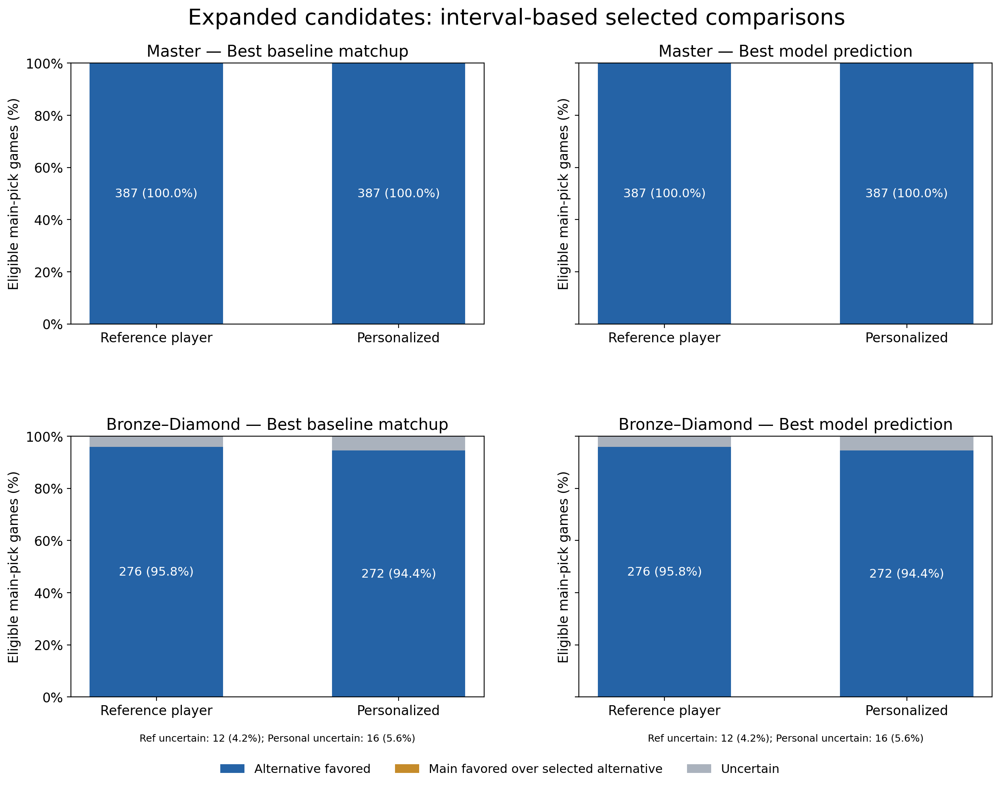

selection_rule,measure,count,denominator,percent
Best baseline matchup,Stay-versus-leave point preference changed,0,387,0.000000
Best baseline matchup,Selected alternative changed,0,387,0.000000
Best baseline matchup,Interval classification changed,0,387,0.000000
Best model prediction,Stay-versus-leave point preference changed,0,387,0.000000
Best model prediction,Selected alternative changed,22,387,5.684755
Best model prediction,Interval classification changed,0,387,0.000000


**Master, familiar-only versus expanded:** 324 original eligible games and 63 newly eligible games. The following changes use matched original games; only the best-model row holds the original model-based selection rule fixed.

selection_rule,measure,count,denominator,percent
Best baseline matchup,Selected alternative changed on familiar-eligible games,322,324,99.382716
Best baseline matchup,Stay/leave point preference changed on familiar-eligible games,115,324,35.493827
Best baseline matchup,Interval classification changed on familiar-eligible games,267,324,82.407407
Best model prediction,Selected alternative changed on familiar-eligible games,312,324,96.296296
Best model prediction,Stay/leave point preference changed on familiar-eligible games,115,324,35.493827
Best model prediction,Interval classification changed on familiar-eligible games,267,324,82.407407


selection_rule,measure,count,denominator,percent
Best baseline matchup,Zero recorded champion games,362,387,93.540052
Best baseline matchup,"Champion history, no same-role history",22,387,5.684755
Best baseline matchup,Prior same-role history,3,387,0.775194
Best model prediction,Zero recorded champion games,231,387,59.689922
Best model prediction,"Champion history, no same-role history",144,387,37.209302
Best model prediction,Prior same-role history,12,387,3.100775


#### Master — actual saved examples (personalized; best baseline matchup)

...

#### Bronze–Diamond — actual saved examples (personalized; best baseline matchup)

**Zero-history alternative favored:** 2026-10-05 01:43 UTC, mid, Akshan → XinZhao. Recorded champion games 82 → 0; raw matchup 35.29% → 100.00% (candidate benchmark n=1). Modeled win probability 44.83% → 78.51%; alternative − main **+33.68 pp [+14.68, +50.60]** (95% credible interval); **Alternative favored**.

**Main favored over zero-history alternative:** no example in these completed comparisons.

**Uncertain comparison:** 2026-10-05 01:36 UTC, top, Jhin → Khazix. Recorded champion games 126 → 0; raw matchup 45.75% → 71.43% (candidate benchmark n=7). Modeled win probability 50.08% → 62.14%; alternative − main **+12.06 pp [-1.73, +26.65]** (95% credible interval); **Uncertain**.

**Interpretation:** the highest published raw matchup is a theoretical benchmark pick; the model additionally conditions on recorded experience, historical champion WR and fitted champion/identity effects. The highest model-mean choice answers a different question. A higher mean is weaker evidence than a paired interval excluding zero. Sparse published matchup counts can produce extreme raw benchmarks, and their sampling error is outside these posterior intervals. The tables retain n<100 flags without filtering such candidates. Zero recorded experience is bounded Season 16 history. Draft availability and alternative outcomes are unknown; these retrospective exploratory selected-comparison intervals are not selection-adjusted. **The earlier 17.6% Master / 2.1% broad findings remain the preserved familiar-only comparison.**

In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
from pathlib import Path
import sys
_expanded_start=Path.cwd().resolve()
_expanded_project=next(p for p in [_expanded_start,*_expanded_start.parents] if (p/'hlr_model/expanded_main_pick_report.py').is_file())
if str(_expanded_project) not in sys.path:sys.path.insert(0,str(_expanded_project))
from hlr_model import expanded_main_pick_report as expanded_report
EXPANDED_PRESENTATION=expanded_report.display_presentation(_expanded_project)

**What changed, holding games fixed:** on the original familiar-eligible games, the personalized best-model alternative is interval-favored in **324/324 Master games (100.0%)**, versus the preserved **57/324 (17.6%)**, and **220/233 broad games (94.4%)**, versus **5/233 (2.1%)**. The additional **63 Master / 55 broad games** are reported separately. The two expanded rules happen to have identical decision-frequency totals, but their personalized champion selections differ in **321/387 Master** and **197/288 broad** games; highest raw benchmark and highest model mean remain different rules.

**Personalization:** staying versus leaving main changes in **0/387 Master** and **1/288 broad games (0.35%)** under either rule. This is separate from changing which alternative is selected. All selected benchmark samples are below 100 games, with median **one**; the striking interval-favored totals condition on noisy benchmarks treated as fixed, not on demonstrated gains from switching.

**A zero-history alternative can still have a lower model mean:** in the saved Silver mid-lane example on 2026-10-06 03:43 UTC, the actual main is **Kayle (98 recorded games)** and the highest-baseline alternative is **Nilah (0 recorded games)**. The raw benchmark rises from **55.13% to 64.00%** (candidate benchmark n=25), while personalized mean win probability is **59.90% for main versus 59.39% for the alternative**. The difference is **-0.51 pp [-13.14, +12.85]**, so this is **uncertain**, not a 95%-interval-supported main preference. The combined fitted terms can offset a better raw benchmark; this does not isolate a causal benefit of practice.


<a id="supported-decisions"></a>
## 11. Minimum 50 LoLalytics matchup games

Both the **main and every candidate alternative** require at least 50 external games for the exact champion–opponent–role–tier–Global–patch-16.19 matchup (queue 420). Raw-table counts were independently checked against the named opponent-row `n`, not overall champion counts or table lengths. No count/rate parsing mismatches were found.

**A — Best baseline matchup:** highest raw matchup win rate. **B — Best model prediction:** highest posterior mean prediction, selected separately by mode. Both use the smallest champion ID to break exact ties. These tables show **personalized** shared-model comparisons; reference-player results are preserved in the separate supported reports.

This is a benchmark-support requirement, not a player-experience restriction. Zero recorded champion experience and no prior same-role play remain allowed. Existing all-role histories, Beta(1,1) WR (.5 at zero games), total history, coefficients, raw rates and pooled identity uncertainty are unchanged. All needed paired predictions were reused from cache. No collection, fitting, predictive evaluation or external smoothing ran.


**Historical scope: these tables filter recommendations from the ORIGINAL fits. They are not project-wide min50 refits. Use Section 12 for the newly fitted analysis.**

In [1]:
from pathlib import Path
import sys
_min50_start=Path.cwd().resolve()
_min50_root=next(p for p in [_min50_start,*_min50_start.parents] if (p/'hlr_model/supported_main_pick_report.py').is_file())
if str(_min50_root) not in sys.path:sys.path.insert(0,str(_min50_root))
from hlr_model import supported_main_pick_report as supported_report
MIN50_REPORTS=supported_report.presentation_tables(_min50_root)


Result,Master: 339 games,Bronze–Diamond: 264 games
Alternative had the higher average prediction.,237 (69.9%),142 (53.8%)
Alternative favored: paired 95% interval entirely above zero.,27 (8.0%),4 (1.5%)
Main favored: paired 95% interval entirely below zero.,0 (0.0%),0 (0.0%)
Comparison remained uncertain.,312 (92.0%),260 (98.5%)


Result,Master: 339 games,Bronze–Diamond: 264 games
Alternative had the higher average prediction.,260 (76.7%),151 (57.2%)
Alternative favored: paired 95% interval entirely above zero.,29 (8.6%),5 (1.9%)
Main favored: paired 95% interval entirely below zero.,0 (0.0%),0 (0.0%)
Comparison remained uncertain.,310 (91.4%),259 (98.1%)


**Coverage:** Master retains **339/392 actual main-pick games (85 players)**; 53 games fail the main’s external 50-game requirement. Bronze–Diamond retains **264/288 games (87 players)**; 24 fail that requirement. Every supported main has an eligible better-raw-matchup alternative, so there are no further no-comparison losses. Excluded games are not counted as model-confirmed main preferences.

**Selected external benchmark support (median; range):** Master main **475; 51–8,177**, alternative A **74; 51–1,735**, alternative B **80; 51–6,042**. Broad main **1,476; 50–51,121**, alternative A **85; 50–1,976**, alternative B **95; 50–35,455**. These are external matchup games, not the player’s recorded prior games.

**Zero recorded champion experience, personalized selections:** A selects zero-history alternatives in **298/339 Master games (87.9%)** and **235/264 broad games (89.0%)**; B does so in **215/339 (63.4%)** and **169/264 (64.0%)**. Other-role and prior same-role experience categories remain separate in the saved summaries.

**Personalization changes staying versus leaving main:** A changes **21/339 Master games (6.2%)** and **17/264 broad games (6.4%)**; B changes **13/339 (3.8%)** and **16/264 (6.1%)**. Changing which alternative is selected is recorded separately.

With minimum external support, most comparisons remain uncertain: a higher mean is much more common than a paired credible interval excluding zero. The threshold removes tiny-sample extremes but does not propagate external benchmark uncertainty or adjust for selecting an alternative. These remain retrospective modeled comparisons, not demonstrated benefits from switching. Familiar-only and unfiltered expanded reports are preserved. Supported results are saved separately under `reports/expanded_published_candidates_min50_v1/` in each completed cohort analysis.


<a id="min50-refits"></a>
## 12. NEW project-wide min50 refits — both specifications

**Use this section for the new ≥50-game analysis.** Earlier sections preserve original fits and reports; Section 11 applies ≥50 support only to recommendations using the OLD fits. Here ≥50 verified LoLalytics games is required for observations entering fitting/evaluation and for both choices in recommendations.

All four models were refitted with the unchanged equations, priors and grouping definitions. Histories, pregame features and original match-level boundaries/purges remain intact; training standardization and identity/contrast mappings are rebuilt. Master rank remains in its intercept. No collection or external smoothing occurred. This is a **retrospective reanalysis of previously examined outcomes**, not fresh confirmation.

Full modeling/EDA provenance: [min50_modeling.ipynb](min50_modeling.ipynb). All tables/figures below read only the new completed versions and retained posterior outputs.


In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
from pathlib import Path
import sys
import matplotlib.pyplot as plt
_min50_here=Path.cwd().resolve()
MIN50_ROOT=next(p for p in [_min50_here,*_min50_here.parents] if (p/'hlr_model/min50_project_analysis.py').is_file())
if str(MIN50_ROOT) not in sys.path:sys.path.insert(0,str(MIN50_ROOT))
from hlr_model import min50_project_analysis as min50_analysis
from hlr_model import min50_project_presentation as min50_plots
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':12,'axes.titlesize':15,'axes.labelsize':12,
    'xtick.labelsize':10,'ytick.labelsize':11,'legend.fontsize':10,'figure.facecolor':'white','axes.facecolor':'white',
    'text.color':'black','axes.labelcolor':'black','xtick.color':'black','ytick.color':'black',
    'axes.spines.top':False,'axes.spines.right':False,'savefig.transparent':False})
MIN50_REFIT_DATA=min50_plots.load(MIN50_ROOT)
print('Reporting interpreter:',sys.executable)
min50_plots.overview(MIN50_REFIT_DATA)

Reporting interpreter: /Users/minhho-hoang/Documents/riot_proj/riot-game-prediction/.venv-modeling-min50/bin/python


**These are new project-wide min50 fits**, not recommendation-only filtering of the original posteriors. Original histories and recorded experience features remain intact. Original chronological boundaries, match partitions and purges are unchanged. Pyro 1.9.2 / Torch 2.15.0; four sequential chains per model, 600 warmup + 1,200 retained draws, target acceptance .9, depth 9, one Torch thread. All four full diagnostic gates passed. Master rank is constant in its intercept; broad retains rank contrasts. Master labels are unverified legacy seeds with Global Master+ benchmarks; broad uses exact tiers and collection-time rank labels.

Bronze–Diamond NEW version: /Users/minhho-hoang/Documents/riot_proj/riot-game-prediction/hlr_model/data/analyses/broad_rank_mastery_min50_v1/20261029T235057044553Z_8627ea42
Master NEW version: /Users/minhho-hoang/Documents/riot_proj/riot-game-prediction/hlr_model/data/analyses/master_cohort_mastery_min50_v1/20261029T235056723818Z_f5411038


cohort,split,original_included,retained,removed,removed_percent,retained_players,retained_matches
Bronze–Diamond,train,3907,3710,197,5.04%,264,3696
Bronze–Diamond,validation,852,797,55,6.46%,145,795
Bronze–Diamond,test,928,874,54,5.82%,151,871
Master,train,5086,4462,624,12.27%,176,4187
Master,validation,1049,895,154,14.68%,124,864
Master,test,1065,943,122,11.46%,126,902


cohort,model,chains,warmup,draws_per_chain,max_Rhat,min_bulk_ESS,min_tail_ESS,divergences,min_acceptance
Bronze–Diamond,shared,4,600,1200,1.00768,2984,2136,0,1.000
Bronze–Diamond,grouped,4,600,1200,1.00651,2641,2142,0,1.000
Master,shared,4,600,1200,1.00718,3045,2116,0,1.000
Master,grouped,4,600,1200,1.00683,2412,2169,0,1.000


Stable numerical sampling does not establish predictive usefulness. Tree-depth saturation and BFMI remain unavailable from the established wrapper. Validation was evaluated before test, with parameters frozen and shared primary/grouped secondary predeclared. These outcomes were previously examined: **retrospective reanalysis, not fresh confirmation**.

### 12.1 Personalized main-versus-alternative comparisons — NEW shared and grouped fits

Result,Master: 339 games,Bronze–Diamond: 264 games
Alternative has the higher mean prediction.,139 (41.0%),121 (45.8%)
Alternative favored: paired 95% interval above zero.,4 (1.2%),1 (0.4%)
Main favored: paired 95% interval below zero.,2 (0.6%),0 (0.0%)
Uncertain: paired interval includes zero.,333 (98.2%),263 (99.6%)


Result,Master: 339 games,Bronze–Diamond: 264 games
Alternative has the higher mean prediction.,202 (59.6%),140 (53.0%)
Alternative favored: paired 95% interval above zero.,7 (2.1%),1 (0.4%)
Main favored: paired 95% interval below zero.,1 (0.3%),0 (0.0%)
Uncertain: paired interval includes zero.,331 (97.6%),263 (99.6%)


Result,Master: 339 games,Bronze–Diamond: 264 games
Alternative has the higher mean prediction.,155 (45.7%),130 (49.2%)
Alternative favored: paired 95% interval above zero.,3 (0.9%),2 (0.8%)
Main favored: paired 95% interval below zero.,1 (0.3%),0 (0.0%)
Uncertain: paired interval includes zero.,335 (98.8%),262 (99.2%)


Result,Master: 339 games,Bronze–Diamond: 264 games
Alternative has the higher mean prediction.,206 (60.8%),143 (54.2%)
Alternative favored: paired 95% interval above zero.,9 (2.7%),2 (0.8%)
Main favored: paired 95% interval below zero.,2 (0.6%),0 (0.0%)
Uncertain: paired interval includes zero.,328 (96.8%),262 (99.2%)


The higher-mean row overlaps the three interval categories. Both choices require ≥50 verified external matchup games. Zero recorded experience and no prior same-role play remain eligible. Reference-player results are retained separately in the saved reports and do not represent population averages. Intervals are paired Bayesian credible intervals from the NEW fits; they omit external benchmark uncertainty and selection adjustment.

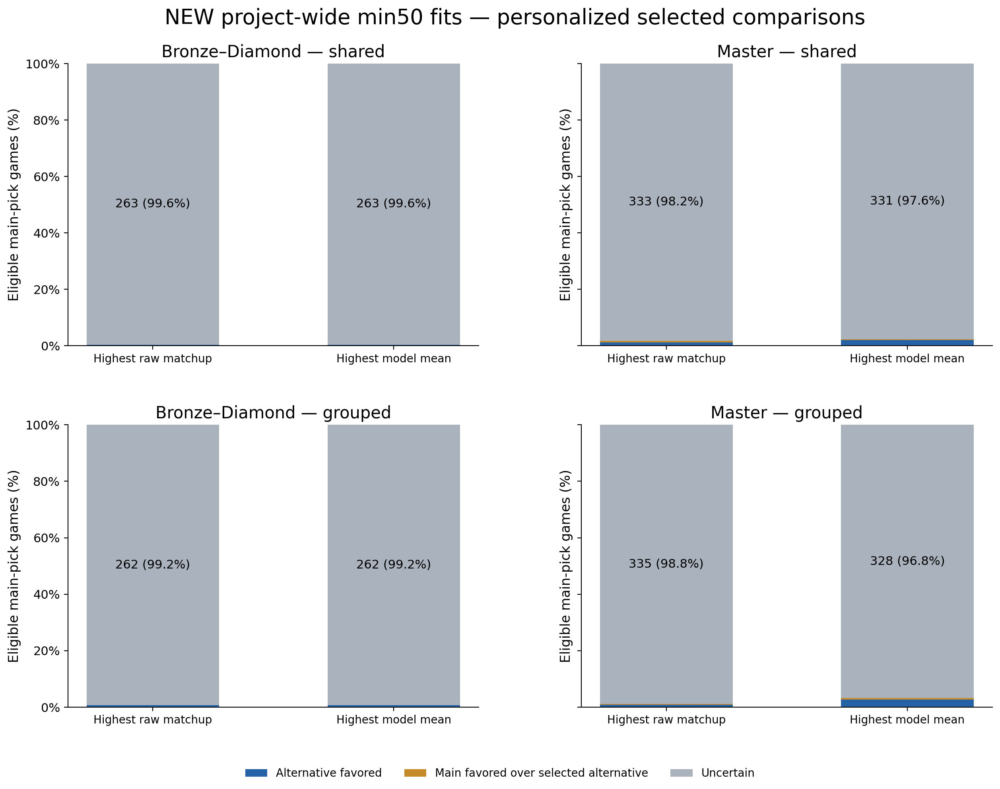

measure,count,denominator,players,unique_matches
Total actual main-pick games,288,288,87,288
Main-pick games with usable main features/benchmarks,264,288,87,264
Games with eligible published better-matchup alternatives,264,288,87,264
Usable main games without an eligible published alternative,0,288,0,0
external_matchup_games_below_50,24,288,10,24
No eligible published better-matchup alternative (not a confirmed main preference),0,288,0,0


selection_rule,mode,section,measure,count,denominator,percent,players
Best baseline matchup,Personalized,selected_experience,Zero recorded champion games,235,264,89.02%,84
Best baseline matchup,Personalized,selected_experience,"Champion history, no same-role history",18,264,6.82%,12
Best baseline matchup,Personalized,selected_experience,Prior same-role history,11,264,4.17%,9
Best model prediction,Personalized,selected_experience,Zero recorded champion games,167,264,63.26%,75
Best model prediction,Personalized,selected_experience,"Champion history, no same-role history",36,264,13.64%,20
Best model prediction,Personalized,selected_experience,Prior same-role history,61,264,23.11%,29
Best baseline matchup,Both modes,personalization_change,Stay-versus-leave point preference changed,15,264,5.68%,14
Best baseline matchup,Both modes,personalization_change,Selected alternative changed,0,264,0.00%,0
Best baseline matchup,Both modes,personalization_change,Interval classification changed,4,264,1.52%,4
Best model prediction,Both modes,personalization_change,Stay-versus-leave point preference changed,15,264,5.68%,14


#### Bronze–Diamond / NEW shared — actual saved examples (personalized; best baseline matchup)

**Zero-history alternative favored:** 2026-10-06 06:30 UTC, top, Hwei → Naafiri. Recorded champion games 12 → 0; raw matchup 36.54% → 66.07% (candidate benchmark n=56). Modeled win probability 40.00% → 58.54%; alternative − main **+18.54 pp [+1.06, +35.95]** (95% credible interval); **Alternative favored**.

**Main favored over zero-history alternative:** no example in these completed comparisons.

...

selection_rule,mode,section,measure,count,denominator,percent,players
Best baseline matchup,Personalized,selected_experience,Zero recorded champion games,298,339,87.91%,80
Best baseline matchup,Personalized,selected_experience,"Champion history, no same-role history",9,339,2.65%,7
Best baseline matchup,Personalized,selected_experience,Prior same-role history,32,339,9.44%,19
Best model prediction,Personalized,selected_experience,Zero recorded champion games,160,339,47.20%,54
Best model prediction,Personalized,selected_experience,"Champion history, no same-role history",25,339,7.37%,16
Best model prediction,Personalized,selected_experience,Prior same-role history,154,339,45.43%,61
Best baseline matchup,Both modes,personalization_change,Stay-versus-leave point preference changed,14,339,4.13%,11
Best baseline matchup,Both modes,personalization_change,Selected alternative changed,0,339,0.00%,0
Best baseline matchup,Both modes,personalization_change,Interval classification changed,6,339,1.77%,6
Best model prediction,Both modes,personalization_change,Stay-versus-leave point preference changed,9,339,2.65%,9


#### Master / NEW grouped — actual saved examples (personalized; best baseline matchup)

**Zero-history alternative favored:** 2026-10-06 02:31 UTC, adc, Samira → AurelionSol. Recorded champion games 97 → 0; raw matchup 44.14% → 76.36% (candidate benchmark n=55). Modeled win probability 47.88% → 66.42%; alternative − main **+18.54 pp [+1.64, +33.90]** (95% credible interval); **Alternative favored**.

**Main favored over zero-history alternative:** 2026-10-05 10:22 UTC, mid, Akshan → Leblanc. Recorded champion games 235 → 0; raw matchup 57.01% → 57.99% (candidate benchmark n=169). Modeled win probability 56.74% → 44.25%; alternative − main **-12.49 pp [-24.43, -1.18]** (95% credible interval); **Main favored over selected alternative**.

**Uncertain comparison:** 2026-10-05 01:32 UTC, adc, Caitlyn → Vladimir. Recorded champion games 114 → 0; raw matchup 52.13% → 63.64% (candidate benchmark n=55). Modeled win probability 53.99% → 51.78%; alternative − main **-2.21 pp [-15.87, +11.45]** (95% credible interval); **Uncertain**.

In [2]:
min50_plots.recommendations(MIN50_REFIT_DATA)

### 12.2 Predictive usefulness on the filtered test rows

cohort,model,mode,rows,players,matches,log_loss,brier,roc_auc,equal_player_log_loss,equal_player_brier
Bronze–Diamond,shared,general,874,151,871,0.69501,0.25093,0.50758,0.69009,0.24850
Bronze–Diamond,shared,personalized,874,151,871,0.69479,0.25082,0.51064,0.69030,0.24860
Bronze–Diamond,grouped,general,874,151,871,0.69492,0.25089,0.50833,0.69052,0.24872
Bronze–Diamond,grouped,personalized,874,151,871,0.69475,0.25080,0.51052,0.69086,0.24888
Bronze–Diamond,training_prevalence,benchmark,874,151,871,0.69315,0.25000,0.50000,0.69315,0.25000
Bronze–Diamond,raw_matchup,benchmark,874,151,871,0.69330,0.25009,0.51305,0.69193,0.24943
Master,training_prevalence,benchmark,943,126,902,0.69312,0.24998,0.50000,0.69307,0.24996
Master,raw_matchup,benchmark,943,126,902,0.68825,0.24759,0.54426,0.69052,0.24873
Master,shared,general,943,126,902,0.68907,0.24798,0.55176,0.69923,0.25303
Master,shared,personalized,943,126,902,0.68947,0.24819,0.54660,0.69813,0.25249


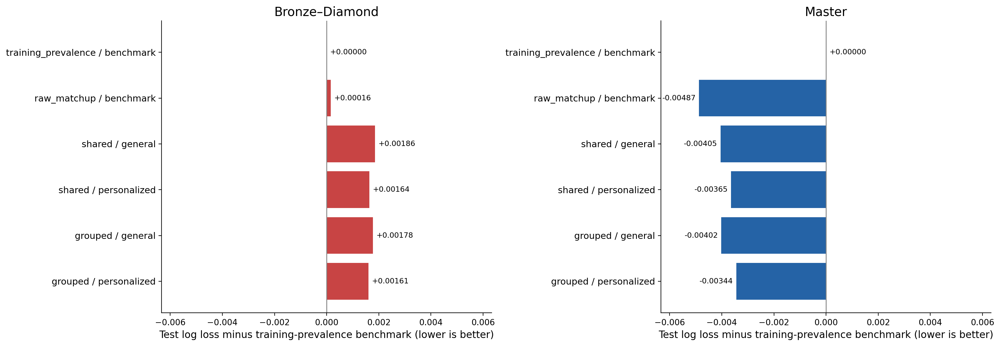

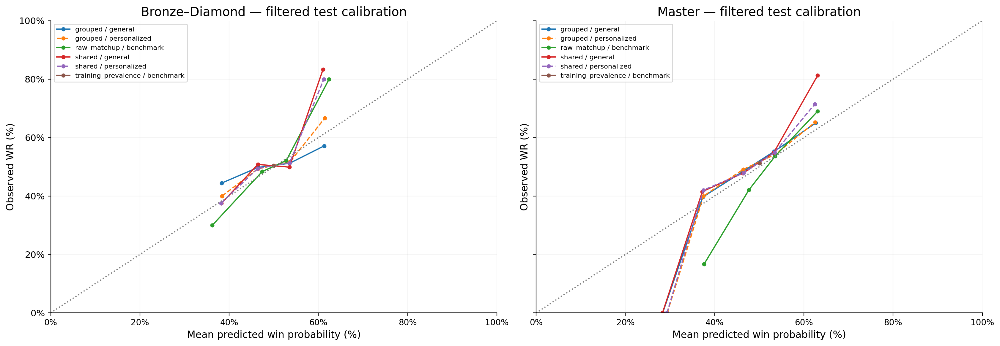

These held-out outcomes were previously examined. Test was evaluated only after validation, with fitted parameters and the predeclared shared/grouped roles frozen. No test tuning occurred. Calibration retains 0–100% axes; sparse extreme bins are unstable. Loss/AUC/equal-player values measure prediction, not switching benefits.

In [3]:
min50_plots.predictive_results(MIN50_REFIT_DATA)

### 12.3 Updated matched training descriptions

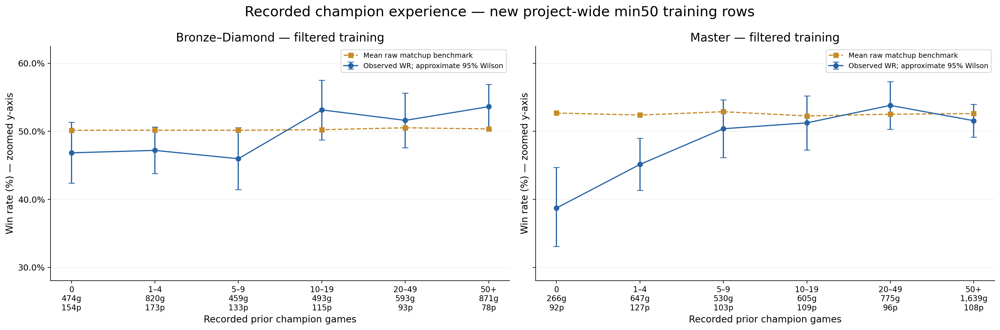

Matched observed/benchmark rows; g = likelihood player-games, p = distinct players. Wilson intervals ignore repeated-player/shared-match dependence; no benchmark interval is invented. Undefined-category exclusions: {'Bronze–Diamond': 0, 'Master': 0}. Recorded histories were not filtered. These are descriptive associations.

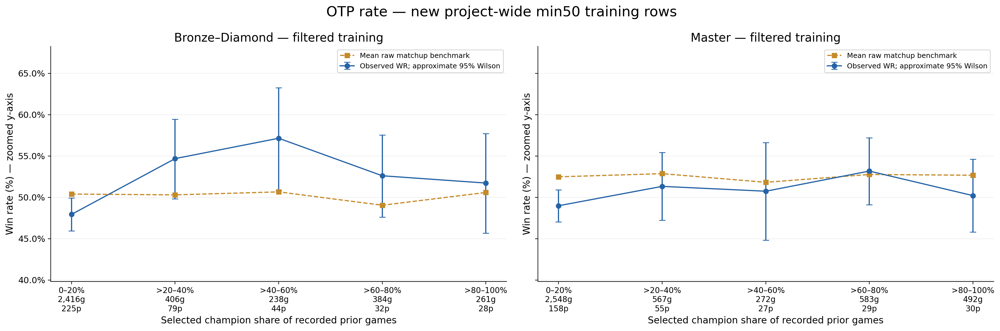

Matched observed/benchmark rows; g = likelihood player-games, p = distinct players. Wilson intervals ignore repeated-player/shared-match dependence; no benchmark interval is invented. Undefined-category exclusions: {'Bronze–Diamond': 5, 'Master': 0}. Recorded histories were not filtered. These are descriptive associations.

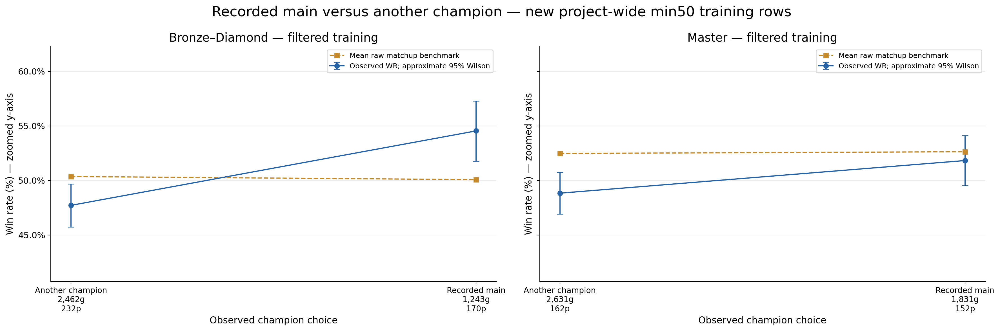

Matched observed/benchmark rows; g = likelihood player-games, p = distinct players. Wilson intervals ignore repeated-player/shared-match dependence; no benchmark interval is invented. Undefined-category exclusions: {'Bronze–Diamond': 5, 'Master': 0}. Recorded histories were not filtered. These are descriptive associations.

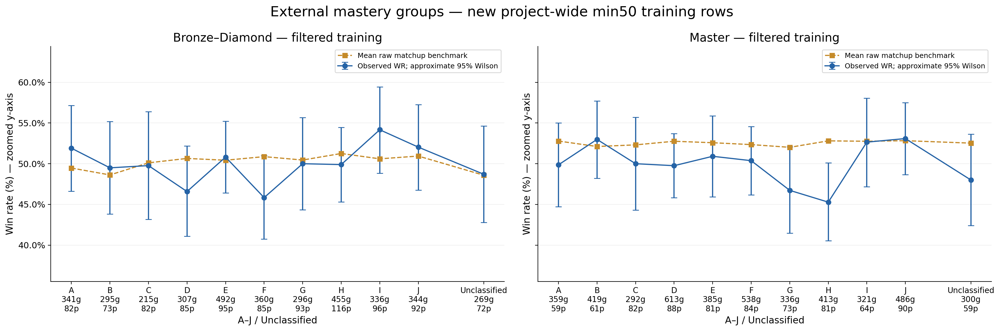

Matched observed/benchmark rows; g = likelihood player-games, p = distinct players. Wilson intervals ignore repeated-player/shared-match dependence; no benchmark interval is invented. Undefined-category exclusions: {'Bronze–Diamond': 0, 'Master': 0}. Recorded histories were not filtered. These are descriptive associations.

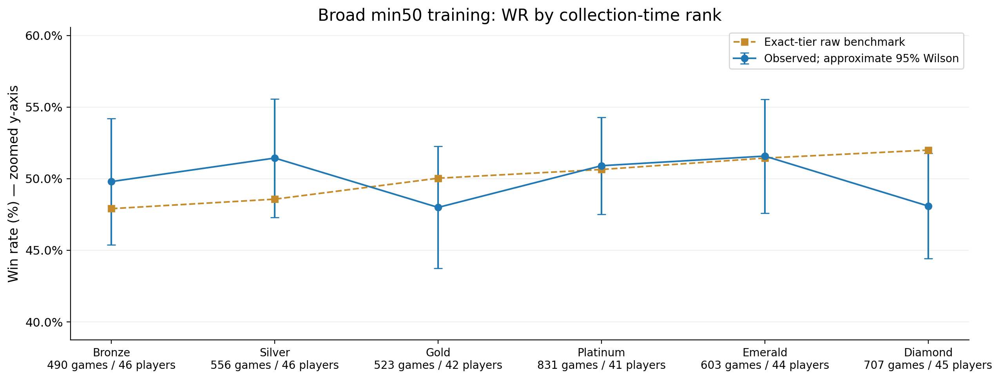

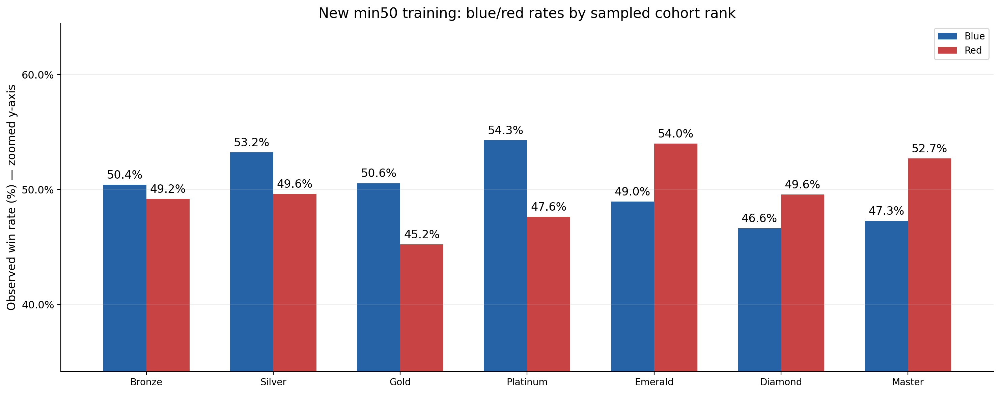

Side bars omit error bars; their shared zoom includes underlying Wilson bounds plus five percentage points. Rank labels describe sampled cohorts; Master uses unverified legacy seed labels. No causal side or rank effect is established.

In [4]:
min50_plots.eda(MIN50_REFIT_DATA)

### 12.4 New parameter estimates, intervals and filtered-training units

In [5]:
min50_plots.parameters(MIN50_REFIT_DATA,grouped=False)

parameter,units,median,low_95,high_95,probability_positive
Intercept,Log-odds; centered continuous covariates; n=0; top/reference rank; zero identity effects,-0.179,-0.448,0.074,0.081
Raw matchup,Log-odds per filtered-training SD,0.120,0.046,0.191,0.999
log(1 + prior total games),Log-odds per filtered-training SD,-0.057,-0.133,0.018,0.070
"Historical champion WR Beta(1,1)",Log-odds per filtered-training SD,0.027,-0.041,0.092,0.772
Raw matchup: +2 percentage points,Log-odds per +0.02 raw matchup probability,0.060,0.023,0.096,0.999
jungle versus top,Log-odds contrast,0.070,-0.150,0.299,0.728
mid versus top,Log-odds contrast,0.137,-0.092,0.367,0.884
adc versus top,Log-odds contrast,0.068,-0.155,0.294,0.725
support versus top,Log-odds contrast,0.166,-0.064,0.387,0.925
SILVER versus Bronze,Log-odds contrast,0.037,-0.223,0.304,0.610


parameter,units,median,low_95,high_95,probability_positive
Intercept,Log-odds; centered continuous covariates; n=0; top/reference rank; zero identity effects,-0.303,-0.587,-0.045,0.011
Raw matchup,Log-odds per filtered-training SD,0.148,0.091,0.207,1.000
log(1 + prior total games),Log-odds per filtered-training SD,-0.033,-0.100,0.034,0.172
"Historical champion WR Beta(1,1)",Log-odds per filtered-training SD,0.010,-0.052,0.074,0.618
Raw matchup: +2 percentage points,Log-odds per +0.02 raw matchup probability,0.077,0.047,0.108,1.000
jungle versus top,Log-odds contrast,0.008,-0.204,0.218,0.531
mid versus top,Log-odds contrast,-0.169,-0.372,0.031,0.050
adc versus top,Log-odds contrast,-0.064,-0.271,0.143,0.282
support versus top,Log-odds contrast,-0.177,-0.396,0.046,0.059
Experience amplitude,Asymptotic log-odds; common amplitude,0.539,0.291,0.787,1.000


cohort,predictor,training_mean,training_SD
Bronze–Diamond,matchup_probability,0.502697,0.039840
Bronze–Diamond,log_total,4.794915,0.841635
Bronze–Diamond,historical_wr_beta11,0.521035,0.115500
Master,matchup_probability,0.525443,0.038341
Master,log_total,5.226919,0.228027
Master,historical_wr_beta11,0.538905,0.105468


Coefficients are log-odds, not win-probability percentage points. The common +2 raw matchup pp row equals β × .02 / the NEW training SD. Experience is b × n/(n+k); n is recorded prior champion games, and k is half-saturation in recorded games. k and SDs are exponentiated from their log parameters, with blank sign probabilities; posterior sign probabilities are not p-values. Shared uses one experience amplitude; grouped totals add the shared amplitude and the reconstructed zero-sum group deviation. The original priors/equations/group definitions are unchanged. No A–J ordering is imposed.

### 12.5 Supported experience curves and grouped secondary estimates

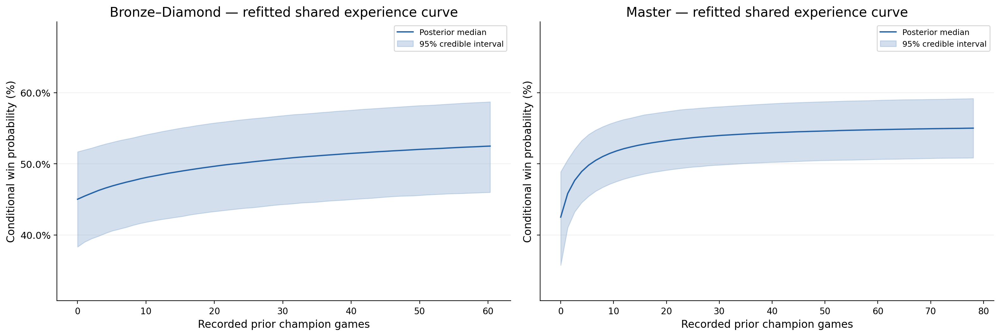

cohort,matchup_percent,historical_WR_percent,total_prior_games,role,rank,max_displayed_experience
Bronze–Diamond,50.500000,51.020408,174.000000,Top,Bronze,60.300000
Master,52.570000,54.166667,186.000000,Top,Master constant,78.050000


Conditional reference-player illustrations, not population averages or total causal benefits of practice. Curves control historical champion WR and other covariates. Displayed experience stops at saved training-support/context caps; counts never exceed total prior games. Shared/grouped curve panels use one common zoom including all pointwise credible bands.

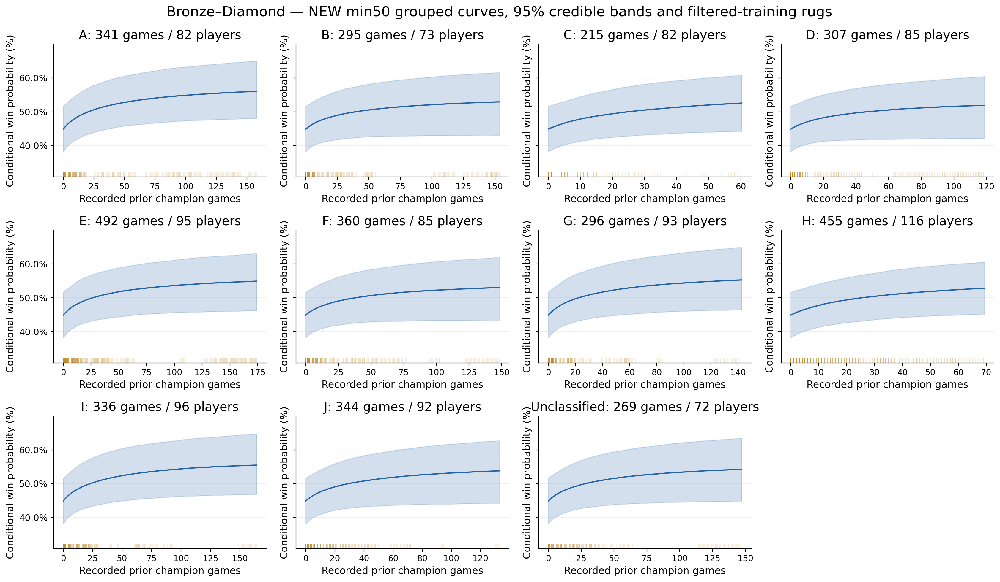

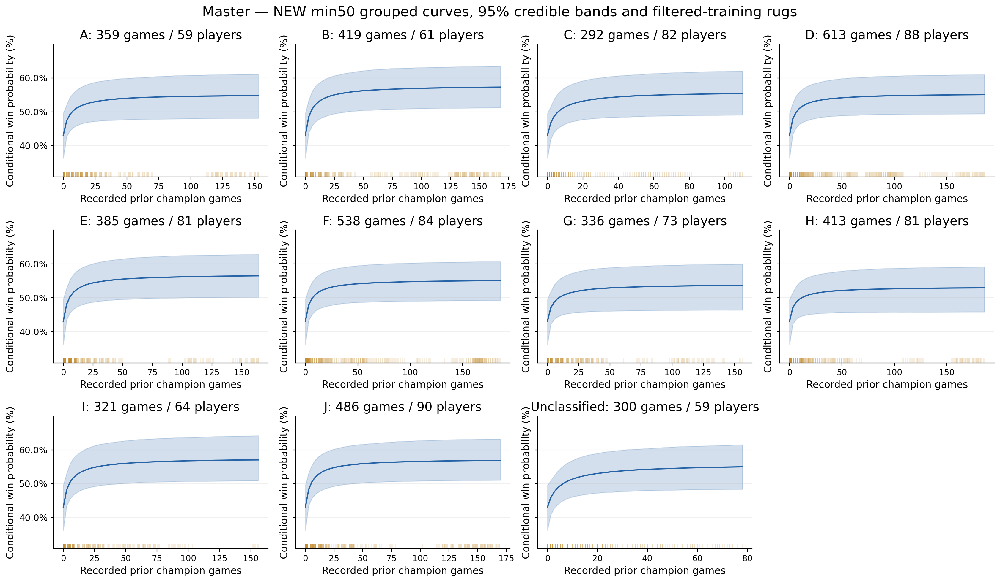

parameter,units,median,low_95,high_95,probability_positive
Intercept,Log-odds; centered continuous covariates; n=0; top/reference rank; zero identity effects,-0.185,-0.454,0.082,0.086
Raw matchup,Log-odds per filtered-training SD,0.120,0.046,0.190,1.000
log(1 + prior total games),Log-odds per filtered-training SD,-0.058,-0.134,0.018,0.068
"Historical champion WR Beta(1,1)",Log-odds per filtered-training SD,0.026,-0.043,0.095,0.783
Raw matchup: +2 percentage points,Log-odds per +0.02 raw matchup probability,0.060,0.023,0.096,1.000
jungle versus top,Log-odds contrast,0.074,-0.154,0.300,0.739
mid versus top,Log-odds contrast,0.148,-0.078,0.379,0.900
adc versus top,Log-odds contrast,0.078,-0.144,0.310,0.749
support versus top,Log-odds contrast,0.166,-0.061,0.398,0.920
SILVER versus Bronze,Log-odds contrast,0.046,-0.212,0.300,0.636


parameter,median,low_95,high_95,probability_positive
A,0.576,0.197,1.166,0.998
B,0.416,-0.021,0.959,0.969
C,0.519,0.065,1.173,0.985
D,0.386,-0.096,0.960,0.946
E,0.500,0.132,1.049,0.996
F,0.421,-0.011,0.958,0.972
G,0.542,0.155,1.164,0.995
H,0.507,0.091,1.121,0.991
I,0.539,0.148,1.152,0.995
J,0.474,0.049,1.053,0.982


parameter,units,median,low_95,high_95,probability_positive
Intercept,Log-odds; centered continuous covariates; n=0; top/reference rank; zero identity effects,-0.280,-0.564,-0.019,0.016
Raw matchup,Log-odds per filtered-training SD,0.149,0.089,0.212,1.000
log(1 + prior total games),Log-odds per filtered-training SD,-0.032,-0.099,0.035,0.170
"Historical champion WR Beta(1,1)",Log-odds per filtered-training SD,0.012,-0.051,0.072,0.639
Raw matchup: +2 percentage points,Log-odds per +0.02 raw matchup probability,0.078,0.046,0.110,1.000
jungle versus top,Log-odds contrast,0.000,-0.226,0.223,0.500
mid versus top,Log-odds contrast,-0.161,-0.371,0.041,0.068
adc versus top,Log-odds contrast,-0.058,-0.271,0.156,0.295
support versus top,Log-odds contrast,-0.173,-0.396,0.057,0.070
Experience amplitude,Asymptotic log-odds; common amplitude,0.521,0.270,0.782,1.000


parameter,median,low_95,high_95,probability_positive
A,0.496,0.138,0.802,0.996
B,0.599,0.290,0.915,1.000
C,0.528,0.181,0.864,0.998
D,0.505,0.189,0.804,0.998
E,0.567,0.237,0.890,0.998
F,0.503,0.207,0.787,1.000
G,0.447,0.090,0.762,0.989
H,0.413,0.054,0.718,0.987
I,0.593,0.275,0.934,1.000
J,0.583,0.267,0.910,1.000


Coefficients are log-odds, not win-probability percentage points. The common +2 raw matchup pp row equals β × .02 / the NEW training SD. Experience is b × n/(n+k); n is recorded prior champion games, and k is half-saturation in recorded games. k and SDs are exponentiated from their log parameters, with blank sign probabilities; posterior sign probabilities are not p-values. Shared uses one experience amplitude; grouped totals add the shared amplitude and the reconstructed zero-sum group deviation. The original priors/equations/group definitions are unchanged. No A–J ordering is imposed.

In [6]:
min50_plots.curves(MIN50_REFIT_DATA)
min50_plots.parameters(MIN50_REFIT_DATA,grouped=True)

### 12.6 What the refits support telling David

In [7]:
min50_plots.interpretation(MIN50_REFIT_DATA)

**Experience and matchup in the new shared fits:**

**Bronze–Diamond:** experience amplitude **0.459** (95% credible interval 0.192 to 0.853) log-odds; half-saturation **27.6 recorded games** (7.3 to 139.3). A +2 raw percentage-point matchup increase corresponds to **0.060** (0.023 to 0.096) log-odds. Both conditional associations are positive, while the wide k interval leaves the rate of saturation uncertain. These are not percentage-point changes in a player’s win probability or causal benefits of practice.

The filtered likelihood contains **1,369 player–champion combinations**, with median **1 fitted games** per combination; **75.7%** have at most two. This limited likelihood support remains distinct from the much longer recorded histories used for experience. The fitted identity-scale intervals and pooled unseen-combination uncertainty limit how precisely the model can personalize a comparison.

**Master:** experience amplitude **0.539** (95% credible interval 0.291 to 0.787) log-odds; half-saturation **4.4 recorded games** (1.4 to 18.7). A +2 raw percentage-point matchup increase corresponds to **0.077** (0.047 to 0.108) log-odds. Both conditional associations are positive, while the wide k interval leaves the rate of saturation uncertain. These are not percentage-point changes in a player’s win probability or causal benefits of practice.

The filtered likelihood contains **1,295 player–champion combinations**, with median **1 fitted games** per combination; **72.3%** have at most two. This limited likelihood support remains distinct from the much longer recorded histories used for experience. The fitted identity-scale intervals and pooled unseen-combination uncertainty limit how precisely the model can personalize a comparison.

...

shared, Best baseline matchup: alternative interval-favored in **4/339 (1.2%)**, uncertain **98.2%**; selected zero-history alternative **87.9%**; personalization changes staying/leaving **2.1%**.

shared, Best model prediction: alternative interval-favored in **7/339 (2.1%)**, uncertain **97.6%**; selected zero-history alternative **44.8%**; personalization changes staying/leaving **1.2%**.

grouped, Best baseline matchup: alternative interval-favored in **3/339 (0.9%)**, uncertain **98.8%**; selected zero-history alternative **87.9%**; personalization changes staying/leaving **4.1%**.

grouped, Best model prediction: alternative interval-favored in **9/339 (2.7%)**, uncertain **96.8%**; selected zero-history alternative **47.2%**; personalization changes staying/leaving **2.7%**.

Recorded games mean bounded collected Season 16 history, not lifetime practice. History events with low-support external benchmarks still contribute to experience, WR and main definitions. Sparse fitted player–champion likelihood support is distinct from long recorded histories. Learned identity effects and pooled unseen-identity uncertainty are retained in paired predictions. Stable chains and small predictive differences do not establish reliable pick advice. These retrospective conditional comparisons have unknown draft availability and unplayed outcomes; credible intervals omit external benchmark uncertainty and selection adjustment, and cannot establish causal switching benefits.

### 12.7 Higher average predicted win probability—regardless of uncertainty

Saved posterior-mean point preferences from the NEW project-wide min50 refits, separate from the interval-based categories above.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

_point_here = Path.cwd().resolve()
_point_root = next(p for p in [_point_here, *_point_here.parents]
                   if (p / 'hlr_model/min50_project_presentation.py').is_file())
if str(_point_root) not in sys.path:
    sys.path.insert(0, str(_point_root))
from hlr_model import min50_project_presentation as min50_plots

# Load and verify only the completed NEW refit reports and their fit-chain provenance.
_point_data = min50_plots.load(_point_root)
_point_rows = []
for _cohort, _expected_n in [('Master', 339), ('Bronze–Diamond', 264)]:
    for _model in ['shared', 'grouped']:
        _decisions = _point_data[_cohort]['reports'][_model]['decisions']
        _key = ['puuid', 'match_id', 'model', 'selection_rule', 'mode']
        assert _decisions.model.eq(_model).all()
        assert not _decisions.duplicated(_key).any(), 'Repeated game within model/rule/mode'
        assert set(_decisions['mode']) == {'Personalized', 'Reference player'}
        assert set(_decisions.selection_rule) == {'Best baseline matchup', 'Best model prediction'}
        _game_keys = None
        for _, _frame in _decisions.groupby(['selection_rule', 'mode']):
            assert len(_frame) == _expected_n
            _keys = set(map(tuple, _frame[['puuid', 'match_id']].to_numpy()))
            assert len(_keys) == _expected_n
            if _game_keys is None:
                _game_keys = _keys
            assert _keys == _game_keys
        for _rule, _saved_rule in [('A', 'Best baseline matchup'), ('B', 'Best model prediction')]:
            _frame = _decisions.loc[_decisions['mode'].eq('Personalized') &
                                    _decisions.selection_rule.eq(_saved_rule)]
            _delta = _frame.difference_pp.to_numpy(dtype=float)
            assert np.isfinite(_delta).all()
            # The saved paired difference is the posterior mean of alternative-minus-main
            # probabilities, not a plug-in prediction using median coefficients.
            np.testing.assert_allclose(_delta,
                100 * (_frame.alternative_probability - _frame.main_probability),
                rtol=1e-12, atol=1e-12)
            _counts = [int((_delta > 0).sum()), int((_delta < 0).sum()), int((_delta == 0).sum())]
            assert sum(_counts) == len(_frame) == _expected_n
            _point_rows.append({
                'Cohort': _cohort, 'Model': _model.title(), 'Rule': _rule, 'Eligible N': _expected_n,
                'Alternative favored': f'{_counts[0]} ({100 * _counts[0] / _expected_n:.1f}%)',
                'Main favored': f'{_counts[1]} ({100 * _counts[1] / _expected_n:.1f}%)',
                'Exact ties': f'{_counts[2]} ({100 * _counts[2] / _expected_n:.1f}%)'})

MIN50_POINT_PREFERENCES = pd.DataFrame(_point_rows)
_point_title = 'Higher average predicted win probability—regardless of uncertainty'
print(_point_title)
print(MIN50_POINT_PREFERENCES.to_string(index=False))
print('Verified: one row per game/model/rule/mode; 339 Master and 264 broad games; signs sum to N.')
min50_plots.white_table(MIN50_POINT_PREFERENCES, _point_title,
    bold_cols=['Alternative favored', 'Main favored', 'Exact ties'])
display(Markdown('**Personalized predictions from the NEW project-wide min50 refits only.** '
    '**A:** highest raw-matchup alternative; **B:** highest posterior-mean predicted alternative, selected in personalized mode. '
    'Difference = alternative minus main posterior mean predicted win probability. '
    'Alternative favored means saved mean difference > 0; main favored means < 0; exact ties mean == 0, with no rounding tolerance. '
    'These are point preferences regardless of credible intervals, not claims of a resolved advantage.'))


Higher average predicted win probability—regardless of uncertainty
        Cohort   Model Rule  Eligible N Alternative favored Main favored Exact ties
        Master  Shared    A         339         139 (41.0%)  200 (59.0%)   0 (0.0%)
        Master  Shared    B         339         202 (59.6%)  137 (40.4%)   0 (0.0%)
        Master Grouped    A         339         155 (45.7%)  184 (54.3%)   0 (0.0%)
        Master Grouped    B         339         206 (60.8%)  133 (39.2%)   0 (0.0%)
Bronze–Diamond  Shared    A         264         121 (45.8%)  143 (54.2%)   0 (0.0%)
Bronze–Diamond  Shared    B         264         140 (53.0%)  124 (47.0%)   0 (0.0%)
Bronze–Diamond Grouped    A         264         130 (49.2%)  134 (50.8%)   0 (0.0%)
Bronze–Diamond Grouped    B         264         143 (54.2%)  121 (45.8%)   0 (0.0%)
Verified: one row per game/model/rule/mode; 339 Master and 264 broad games; signs sum to N.


Cohort,Model,Rule,Eligible N,Alternative favored,Main favored,Exact ties
Master,Shared,A,339,139 (41.0%),200 (59.0%),0 (0.0%)
Master,Shared,B,339,202 (59.6%),137 (40.4%),0 (0.0%)
Master,Grouped,A,339,155 (45.7%),184 (54.3%),0 (0.0%)
Master,Grouped,B,339,206 (60.8%),133 (39.2%),0 (0.0%)
Bronze–Diamond,Shared,A,264,121 (45.8%),143 (54.2%),0 (0.0%)
Bronze–Diamond,Shared,B,264,140 (53.0%),124 (47.0%),0 (0.0%)
Bronze–Diamond,Grouped,A,264,130 (49.2%),134 (50.8%),0 (0.0%)
Bronze–Diamond,Grouped,B,264,143 (54.2%),121 (45.8%),0 (0.0%)


**Personalized predictions from the NEW project-wide min50 refits only.** **A:** highest raw-matchup alternative; **B:** highest posterior-mean predicted alternative, selected in personalized mode. Difference = alternative minus main posterior mean predicted win probability. Alternative favored means saved mean difference > 0; main favored means < 0; exact ties mean == 0, with no rounding tolerance. These are point preferences regardless of credible intervals, not claims of a resolved advantage.